# Laboratorio 4


Integrantes:

- Nicolas Mario Romero Colmenares - 202321309
- Nicolas Rey Lopez - 202321258



Fuente de los datos. Las imágenes y sus máscaras de referencia son una selección de 20 imágenes dermatoscópicas del conjunto ISIC 2016, tarea de segmentación de lesiones: https://challenge.isic-archive.com/landing/2016/37/. Las máscaras de referencia fueron elaboradas por especialistas. Vienen con valores 0 y 255 y las convertimos a 0 y 1. Al reducir las imágenes a 128×128 redimensionamos también las máscaras con interpolación por vecino más cercano, para conservar los valores binarios.

## 0. Importacion de librerias

In [18]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TAMANO = (128, 128)

## 1. Pipeline de preparación y representación 

### 1.1 Transformaciones del pipeline

Cada imagen se representa como una matriz con un píxel por fila y cinco características: `[β·R, β·G, β·B, λ·x, λ·y]`. El color y las coordenadas están normalizados a [0, 1], así que β y λ comparan magnitudes en la misma escala.

El pipeline de Scikit-learn tiene dos pasos. ImagenAPixeles convierte la imagen de forma H por W por 3 en una matriz de H·W filas y 5 columnas, con color y posición normalizados. PonderadorCaracteristicas multiplica las columnas de color por β y las de posición por λ.

Separar los pasos permite cambiar β y λ con set_params, usando pesos__beta y pesos__lam, sin tocar la implementación. Los casos extremos se comprueban en 1.4: con β = 0 solo queda la posición y con λ = 0 solo queda el color.

Las imágenes se reducen a 128×128, que son 16 384 píxeles, para que K-medias sea rápido. Las máscaras se redimensionan con interpolación por vecino más cercano para conservar los valores binarios, y se convierten de {0, 255} a {0, 1}.

In [19]:
class ImagenAPixeles(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        img = np.asarray(X)
        if img.ndim != 3 or img.shape[2] != 3:
            raise ValueError("Se espera una imagen RGB de forma (H, W, 3).")

        img = img.astype(np.float64)
        if img.max() > 1.0:
            img = img / 255.0

        h, w, _ = img.shape
        # Coordenadas normalizadas a [0, 1]
        xs = np.linspace(0, 1, w)
        ys = np.linspace(0, 1, h)
        xx, yy = np.meshgrid(xs, ys)

        color = img.reshape(-1, 3)
        pos = np.column_stack([xx.ravel(), yy.ravel()])
        return np.hstack([color, pos])  # (H*W, 5)

class PonderadorCaracteristicas(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=1.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        pesos = np.array([self.beta] * 3 + [self.lam] * 2, dtype=np.float64)
        return X * pesos


def construir_pipeline(beta=1.0, lam=1.0):
    return Pipeline([
        ("pixeles", ImagenAPixeles()),
        ("pesos", PonderadorCaracteristicas(beta=beta, lam=lam)),
    ])

### 1.2 Carga de imágenes y preparación de máscaras

In [20]:
ruta_imagenes = "./ISBI2016_ISIC_Part1_Training_Data"
ruta_mascaras = "./ISBI2016_ISIC_Part1_Training_GroundTruth"

def cargar_imagen(ruta, tamano=TAMANO):
    img = Image.open(ruta).convert("RGB")
    img = img.resize(tamano, Image.BILINEAR)
    return np.asarray(img)  # uint8 (H, W, 3)


def cargar_mascara(ruta, tamano=TAMANO):
    m = Image.open(ruta).convert("L")
    m = m.resize(tamano, Image.NEAREST)
    m = np.asarray(m)
    return (m > 127).astype(np.uint8)


def cargar_dataset(ruta_img, ruta_mask, tamano=TAMANO):
    rutas = sorted(glob.glob(os.path.join(ruta_img, "*.jpg")))
    imagenes, mascaras, nombres = [], [], []
    for r in rutas:
        base = os.path.splitext(os.path.basename(r))[0]
        r_mask = os.path.join(ruta_mask, f"{base}_Segmentation.png")
        if not os.path.exists(r_mask):
            print(f"Advertencia: sin máscara para {base}, se omite.")
            continue
        imagenes.append(cargar_imagen(r, tamano))
        mascaras.append(cargar_mascara(r_mask, tamano))
        nombres.append(base)
    return imagenes, mascaras, nombres


imagenes, mascaras, nombres = cargar_dataset(ruta_imagenes, ruta_mascaras)
print(f"Imágenes cargadas: {len(imagenes)}")
assert len(imagenes) == 20, "Se esperaban 20 imágenes."

Imágenes cargadas: 20


### 1.3 División en conjuntos de ajuste y prueba

La partición ajuste/prueba es la indicada en el enunciado: 15 imágenes de ajuste y 5 de prueba. Desde aquí, las imágenes de prueba y sus máscaras no se usan para elegir β, λ, K ni el criterio de construcción de la máscara. Solo se consultan en la sección 5 para calcular métricas.

In [21]:
# Particion definida en el enunciado (no por orden de archivo)
NOMBRES_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094", "ISIC_0000108",
    "ISIC_0000114", "ISIC_0000116", "ISIC_0000122", "ISIC_0000133", "ISIC_0000137",
    "ISIC_0000150", "ISIC_0000153", "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
NOMBRES_PRUEBA = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123", "ISIC_0000128",
]
assert len(set(NOMBRES_AJUSTE) | set(NOMBRES_PRUEBA)) == 20

idx_ajuste = [nombres.index(n) for n in NOMBRES_AJUSTE]
idx_prueba = [nombres.index(n) for n in NOMBRES_PRUEBA]

imgs_ajuste = [imagenes[k] for k in idx_ajuste]
masks_ajuste = [mascaras[k] for k in idx_ajuste]
nombres_ajuste = NOMBRES_AJUSTE

imgs_prueba = [imagenes[k] for k in idx_prueba]
masks_prueba = [mascaras[k] for k in idx_prueba]
nombres_prueba = NOMBRES_PRUEBA

print(f"Ajuste: {len(imgs_ajuste)} imágenes | Prueba: {len(imgs_prueba)} imágenes")
print("Prueba:", ", ".join(nombres_prueba))

Ajuste: 15 imágenes | Prueba: 5 imágenes
Prueba: ISIC_0000087, ISIC_0000105, ISIC_0000110, ISIC_0000123, ISIC_0000128


### 1.4 Verificación del pipeline y de las máscaras

Las comprobaciones confirman que X tiene 16384 filas y 5 columnas, que color y posición quedan en [0, 1], que β y λ anulan las columnas correspondientes y que todas las máscaras son binarias. La fracción de lesión en las imágenes de ajuste va de 3 % a 39 %, es decir, hay lesiones pequeñas y muy grandes.

In [22]:
# Comprobacion de formas y rangos
pipe = construir_pipeline(beta=1.0, lam=1.0)
X = pipe.fit_transform(imgs_ajuste[0])
print("Forma de X:", X.shape, "(esperado:", (TAMANO[0] * TAMANO[1], 5), ")")
print("Mín/Máx por columna:\n", X.min(axis=0), "\n", X.max(axis=0))

# Comprobacion de que β y λ se modifican sin cambiar la implementación
pipe.set_params(pesos__beta=0.0, pesos__lam=1.0)   # solo posición
X_pos = pipe.fit_transform(imgs_ajuste[0])
print("\nβ=0, λ=1 -> columnas de color nulas:", np.allclose(X_pos[:, :3], 0))

pipe.set_params(pesos__beta=1.0, pesos__lam=0.0)   # solo color
X_col = pipe.fit_transform(imgs_ajuste[0])
print("β=1, λ=0 -> columnas de posición nulas:", np.allclose(X_col[:, 3:], 0))

# Comprobacion de las mascaras
for m in masks_ajuste + masks_prueba:
    assert set(np.unique(m)).issubset({0, 1})
print("\nTodas las máscaras son binarias {0, 1}.")
print("Fracción de lesión por imagen (ajuste):",
      np.round([m.mean() for m in masks_ajuste], 2))

Forma de X: (16384, 5) (esperado: (16384, 5) )
Mín/Máx por columna:
 [0.24705882 0.04705882 0.00784314 0.         0.        ] 
 [0.83921569 0.71372549 0.70588235 1.         1.        ]

β=0, λ=1 -> columnas de color nulas: True
β=1, λ=0 -> columnas de posición nulas: True

Todas las máscaras son binarias {0, 1}.
Fracción de lesión por imagen (ajuste): [0.13 0.23 0.12 0.06 0.19 0.03 0.36 0.39 0.14 0.25 0.32 0.28 0.31 0.33
 0.2 ]


### 1.5 Visualización de ejemplos

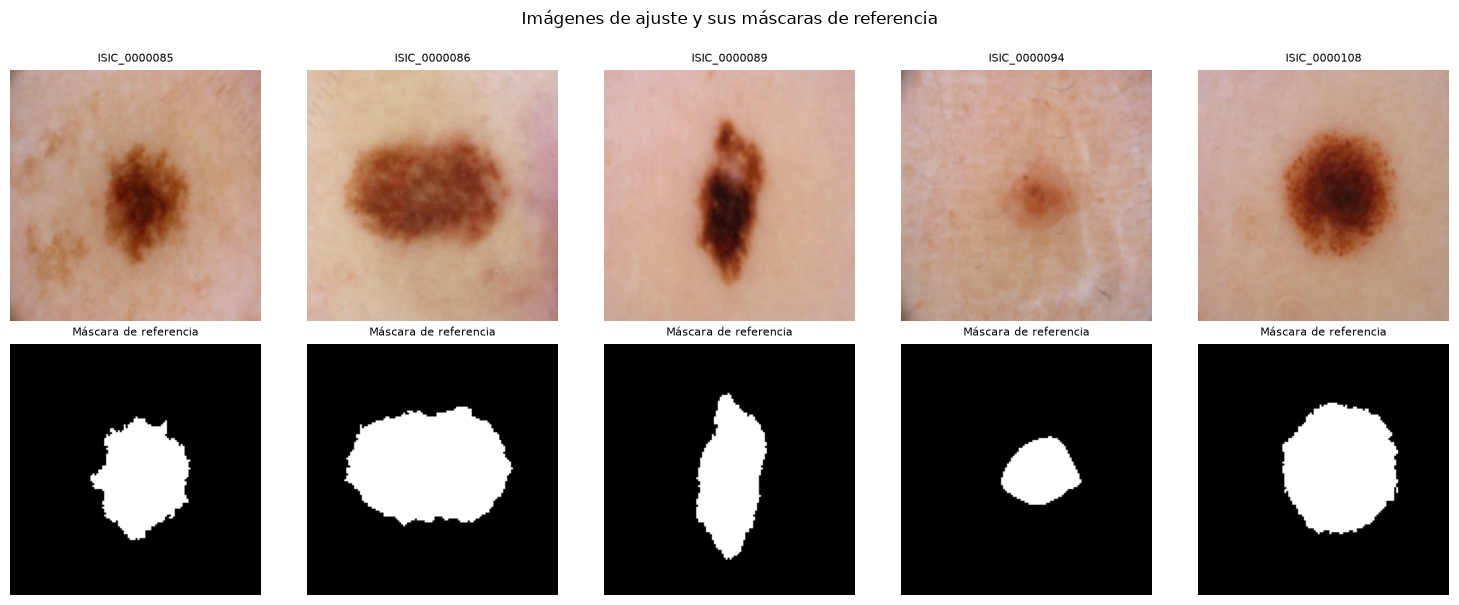

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    axes[0, i].imshow(imgs_ajuste[i])
    axes[0, i].set_title(nombres_ajuste[i], fontsize=8)
    axes[1, i].imshow(masks_ajuste[i], cmap="gray")
    axes[1, i].set_title("Máscara de referencia", fontsize=8)
    for ax in axes[:, i]:
        ax.axis("off")
plt.suptitle("Imágenes de ajuste y sus máscaras de referencia", y=1.0)
plt.tight_layout()
plt.show()

## 2. Agrupación y selección de K

Para cada imagen de ajuste se exploran 10 combinaciones de β y λ, y K-medias con K = 2, …, 8. K se elige con el coeficiente de silueta, sin usar las máscaras de referencia.

Para que todo sea reproducible usamos semilla 42 tanto para la muestra de píxeles como para K-medias, una muestra de 2 000 píxeles para la silueta, que son el 12,2 % de los 16 384, y n_init = 5. Los mismos índices de la muestra se usan en todas las imágenes, combinaciones y valores de K. K-medias se ajusta con todos los píxeles y solo la silueta se calcula sobre la muestra, porque su costo crece con el cuadrado del número de puntos.

Sobre las combinaciones: K-medias solo depende de la razón λ/β, no de sus valores absolutos. Por ejemplo, β = 1 con λ = 0,5 equivale a β = 2 con λ = 1. Por eso se fija β = 1 y se varía λ en {0, 0,1, 0,25, 0,5, 1, 1,5, 2, 3, 5}, más el caso de solo posición, con β = 0 y λ = 1. Así cada combinación produce una agrupación realmente distinta.

### 2.1 Configuración de la exploración

In [24]:
#Parametros reproducibles
SEMILLA = 42
TAM_MUESTRA = 2000
N_INIT = 5
K_RANGO = range(2, 9)

COMBINACIONES = [
    {"nombre": "solo color",     "beta": 1.0, "lam": 0.0},    # λ/β = 0
    {"nombre": "λ/β = 0.1",      "beta": 1.0, "lam": 0.1},
    {"nombre": "λ/β = 0.25",     "beta": 1.0, "lam": 0.25},
    {"nombre": "λ/β = 0.5",      "beta": 1.0, "lam": 0.5},
    {"nombre": "λ/β = 1",        "beta": 1.0, "lam": 1.0},
    {"nombre": "λ/β = 1.5",      "beta": 1.0, "lam": 1.5},
    {"nombre": "λ/β = 2",        "beta": 1.0, "lam": 2.0},
    {"nombre": "λ/β = 3",        "beta": 1.0, "lam": 3.0},
    {"nombre": "λ/β = 5",        "beta": 1.0, "lam": 5.0},
    {"nombre": "solo posición",  "beta": 0.0, "lam": 1.0},    # λ/β = ∞
]
assert len(COMBINACIONES) == 10

n_pix = TAMANO[0] * TAMANO[1]

rng = np.random.default_rng(SEMILLA)
IDX_MUESTRA = np.sort(rng.choice(n_pix, size=TAM_MUESTRA, replace=False))

print(f"Semilla: {SEMILLA} | Muestra de silueta: {TAM_MUESTRA} de {n_pix} píxeles "
      f"({TAM_MUESTRA / n_pix:.1%}) | n_init: {N_INIT} | K ∈ {list(K_RANGO)}")

Semilla: 42 | Muestra de silueta: 2000 de 16384 píxeles (12.2%) | n_init: 5 | K ∈ [2, 3, 4, 5, 6, 7, 8]


### 2.2 Agrupación y selección de K por silueta

In [25]:
def agrupar_imagen(img, beta, lam, k_rango=K_RANGO):
    pipe = construir_pipeline()
    pipe.set_params(pesos__beta=beta, pesos__lam=lam)
    X = pipe.fit_transform(img)
    X_muestra = X[IDX_MUESTRA]

    siluetas, etiquetas = {}, {}
    for k in k_rango:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(X)
        etq = km.labels_
        etiquetas[k] = etq.astype(np.int8)
        etq_m = etq[IDX_MUESTRA]
        if len(np.unique(etq_m)) < 2:
            siluetas[k] = np.nan
        else:
            siluetas[k] = silhouette_score(X_muestra, etq_m)

    k_opt = max((k for k in siluetas if not np.isnan(siluetas[k])),
                key=lambda k: siluetas[k])
    return {"siluetas": siluetas, "k_opt": k_opt, "etiquetas": etiquetas}

resultados = {}
for i, img in enumerate(imgs_ajuste):
    for j, c in enumerate(COMBINACIONES):
        resultados[(i, j)] = agrupar_imagen(img, c["beta"], c["lam"])
    print(f"Imagen {i + 1}/{len(imgs_ajuste)} ({nombres_ajuste[i]}) lista")

Imagen 1/15 (ISIC_0000085) lista
Imagen 2/15 (ISIC_0000086) lista
Imagen 3/15 (ISIC_0000089) lista
Imagen 4/15 (ISIC_0000094) lista
Imagen 5/15 (ISIC_0000108) lista
Imagen 6/15 (ISIC_0000114) lista
Imagen 7/15 (ISIC_0000116) lista
Imagen 8/15 (ISIC_0000122) lista
Imagen 9/15 (ISIC_0000133) lista
Imagen 10/15 (ISIC_0000137) lista
Imagen 11/15 (ISIC_0000150) lista
Imagen 12/15 (ISIC_0000153) lista
Imagen 13/15 (ISIC_0000156) lista
Imagen 14/15 (ISIC_0000157) lista
Imagen 15/15 (ISIC_0000112) lista


### 2.3 Resumen de la selección de K

La silueta elige K = 2 cuando domina el color, con λ/β ≤ 0,25, y K ≈ 5 cuando la posición pesa más, con λ/β ≥ 1. En λ/β = 0,5 el K elegido varía entre imágenes y es 2 o 5. Con solo posición, K = 4 en todas las imágenes, porque los grupos son regiones geométricas que no dependen del contenido.

La silueta sirve para elegir K dentro de una combinación, no para comparar combinaciones: cada una define un espacio de características distinto y sus siluetas no son comparables. Con solo posición, por ejemplo, los grupos son compactos y bien separados aunque no tengan relación con la lesión.

,solo color,λ/β = 0.1,λ/β = 0.25,λ/β = 0.5,λ/β = 1,λ/β = 1.5,λ/β = 2,λ/β = 3,λ/β = 5,solo posición
ISIC_0000085,2,2,2,2,5,5,5,5,5,4
ISIC_0000086,2,2,2,2,5,5,5,5,5,4
ISIC_0000089,2,2,2,2,5,5,5,5,5,4
ISIC_0000094,2,2,5,5,5,5,5,4,4,4
ISIC_0000108,2,2,2,2,5,5,5,5,5,4
ISIC_0000114,2,2,2,5,5,4,4,4,4,4
ISIC_0000116,2,2,2,5,5,5,5,5,5,4
ISIC_0000122,2,2,2,5,5,5,5,5,5,4
ISIC_0000133,2,2,2,2,6,5,5,5,4,4
ISIC_0000137,2,2,2,2,5,5,5,5,5,4


,2,3,4,5,6,7,8
solo color,0.750,0.599,0.493,0.463,0.440,0.414,0.403
λ/β = 0.1,0.717,0.542,0.413,0.377,0.349,0.346,0.352
λ/β = 0.25,0.615,0.408,0.381,0.383,0.390,0.385,0.370
λ/β = 0.5,0.467,0.388,0.407,0.421,0.409,0.388,0.370
λ/β = 1,0.323,0.372,0.406,0.437,0.408,0.387,0.369
λ/β = 1.5,0.324,0.348,0.385,0.431,0.404,0.385,0.376
λ/β = 2,0.330,0.348,0.371,0.421,0.397,0.383,0.379
λ/β = 3,0.340,0.358,0.379,0.406,0.386,0.374,0.376
λ/β = 5,0.346,0.366,0.387,0.391,0.377,0.371,0.368
solo posición,0.355,0.370,0.395,0.374,0.378,0.375,0.366


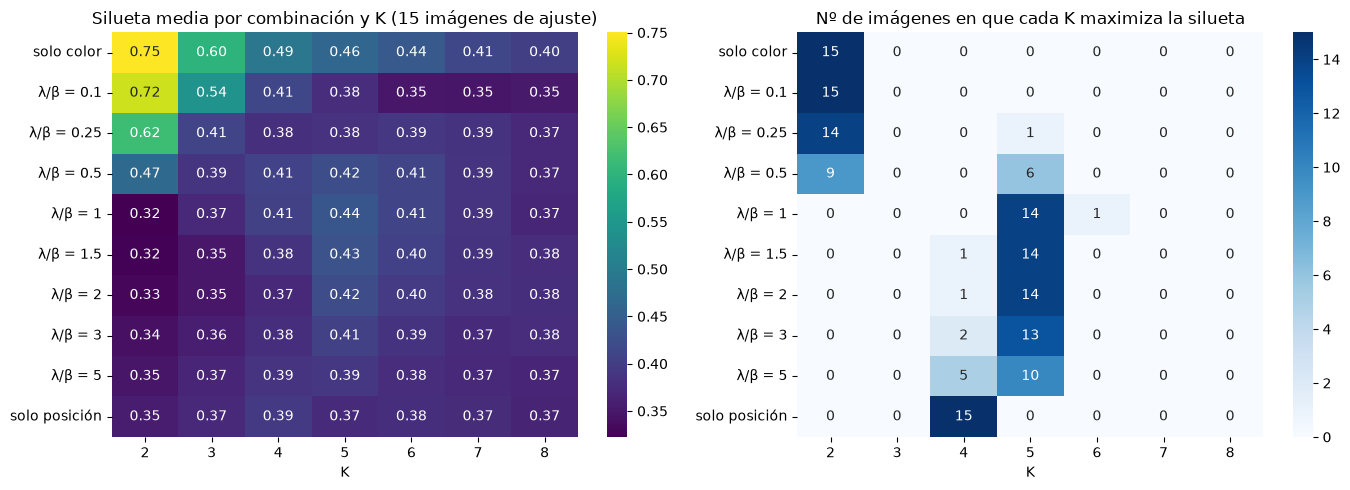

In [26]:
nombres_comb = [c["nombre"] for c in COMBINACIONES]
n_img = len(imgs_ajuste)

# Tabla de K elegido: filas = imagenes, columnas = combinaciones
tabla_k = pd.DataFrame(
    [[resultados[(i, j)]["k_opt"] for j in range(10)] for i in range(n_img)],
    index=nombres_ajuste, columns=nombres_comb)
display(tabla_k)

# Silueta media (sobre las imagenes de ajuste) para cada combinación y K
sil_media = pd.DataFrame(
    [[np.nanmean([resultados[(i, j)]["siluetas"][k] for i in range(n_img)])
      for k in K_RANGO] for j in range(10)],
    index=nombres_comb, columns=list(K_RANGO))
display(sil_media.round(3))

# Frecuencia de cada K elegido por combinacion
frec_k = pd.DataFrame(
    [[(tabla_k.iloc[:, j] == k).sum() for k in K_RANGO] for j in range(10)],
    index=nombres_comb, columns=list(K_RANGO))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(sil_media, annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set_title("Silueta media por combinación y K (15 imágenes de ajuste)")
axes[0].set_xlabel("K"); axes[0].set_ylabel("")

sns.heatmap(frec_k, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Nº de imágenes en que cada K maximiza la silueta")
axes[1].set_xlabel("K"); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 2.4 Inspección visual de una imagen

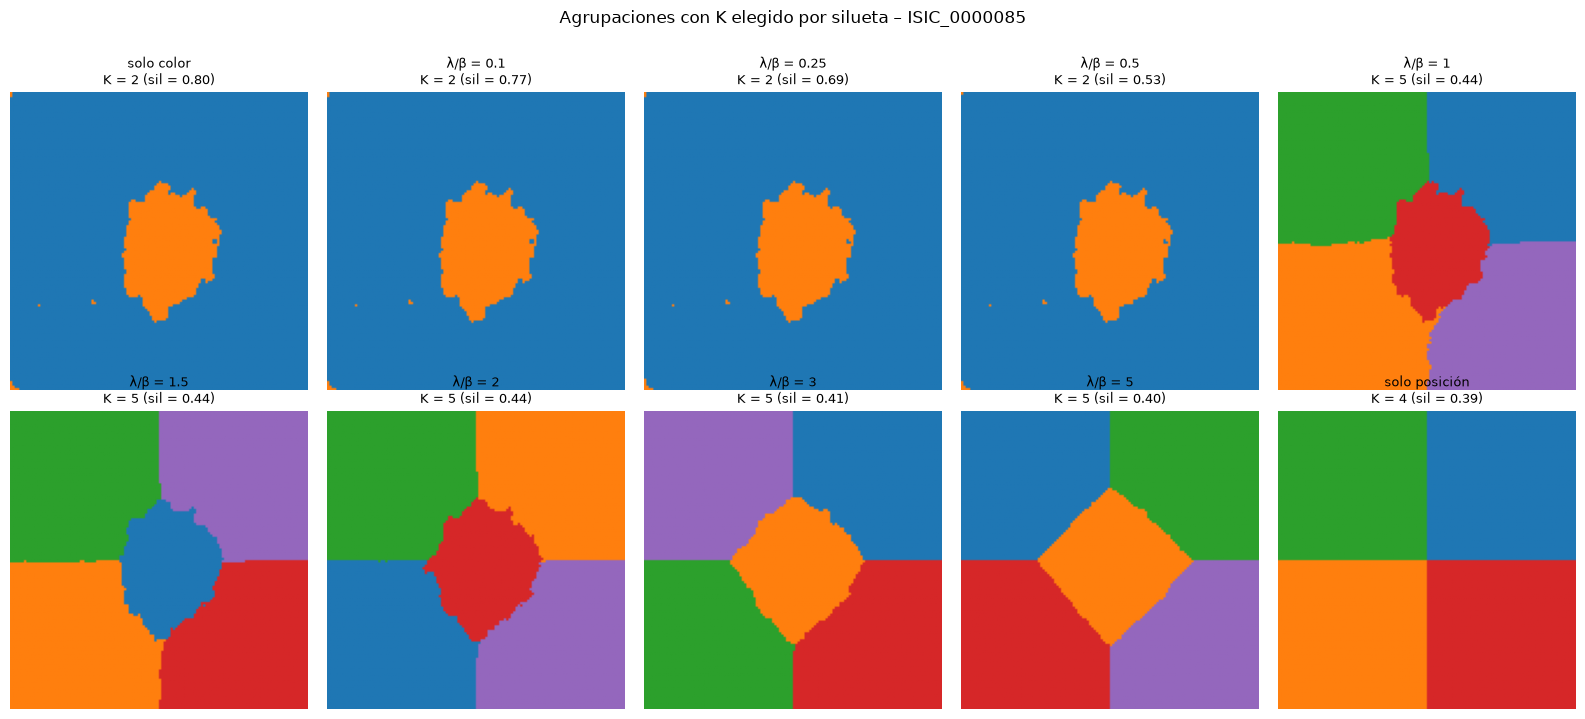

In [27]:
i = 0
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for j, ax in enumerate(axes.ravel()):
    r = resultados[(i, j)]
    etq = r["etiquetas"][r["k_opt"]].reshape(TAMANO[1], TAMANO[0])
    ax.imshow(etq, cmap="tab10", vmin=0, vmax=9)
    ax.set_title(f"{nombres_comb[j]}\nK = {r['k_opt']} "
                 f"(sil = {r['siluetas'][r['k_opt']]:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Agrupaciones con K elegido por silueta – {nombres_ajuste[i]}", y=1.02)
plt.tight_layout()
plt.show()

## 3. Construcción de la máscara de la lesión

Para decidir qué grupos corresponden a la lesión se usan solo propiedades de los grupos y de la imagen, nunca las máscaras de referencia. Son tres. El tamaño es la fracción de píxeles de la imagen que ocupa el grupo. El contraste es la distancia euclídea entre el color medio del grupo y el color de la piel, estimado como la mediana del color en una franja del 10 % del lado en cada borde de la imagen. La razón de borde es la fracción de píxeles del grupo en esa franja dividida entre la fracción de la imagen que ocupa la franja: vale cerca de 1 si el grupo se reparte uniformemente, cerca de 0 si es central y más de 1 si se concentra en los bordes.

En el ejemplo de la celda, el grupo 1 ocupa el 10,6 % de la imagen, tiene contraste alto, de 0,63, y casi nada de borde, 0,02. Es el candidato claro a lesión.

### 3.1 Características de cada grupo

In [28]:
MARGEN = 0.10

def mascara_borde(h, w, margen=MARGEN):
    mb = np.zeros((h, w), dtype=bool)
    mh, mw = int(round(h * margen)), int(round(w * margen))
    mb[:mh, :] = True; mb[-mh:, :] = True
    mb[:, :mw] = True; mb[:, -mw:] = True
    return mb

def caracteristicas_grupos(img, etq):
    h, w, _ = img.shape
    rgb = img.reshape(-1, 3).astype(np.float64) / 255.0
    etq = etq.ravel()
    borde = mascara_borde(h, w).ravel()
    piel = np.median(rgb[borde], axis=0)
    frac_borde_img = borde.mean()

    filas = []
    for g in np.unique(etq):
        m = etq == g
        color = rgb[m].mean(axis=0)
        filas.append({
            "grupo": g,
            "tamano": m.mean(),
            "contraste": np.linalg.norm(color - piel),
            "razon_borde": borde[m].mean() / frac_borde_img,
        })
    return pd.DataFrame(filas).set_index("grupo")


# Ejemplo: grupos de la imagen 0 con "λ/β = 0.5" (índice 3) y su K elegido
r = resultados[(0, 3)]
display(caracteristicas_grupos(imgs_ajuste[0], r["etiquetas"][r["k_opt"]]).round(3))

,tamano,contraste,razon_borde
grupo,,,
0,0.894,0.037,1.116
1,0.106,0.627,0.016


### 3.2 Dos criterios para identificar la lesión

Criterio A, contraste de color con la piel. La lesión es la parte de la imagen cuyo color más se aparta del de la piel. Se estima la piel con el color mediano del borde y se calcula, para cada grupo, la distancia euclídea entre su color medio y ese color de piel.

En dermatoscopía la lesión suele ser más oscura o pigmentada que la piel. Un grupo es lesión si su contraste alcanza al menos la mitad del contraste máximo y supera un mínimo absoluto de 0,08. El grupo de mayor contraste siempre se incluye. Su debilidad es que no usa la ubicación, así que puede confundir con lesión el viñeteado oscuro del dermatoscopio, el vello o las marcas, y falla si la lesión es pálida.

Criterio B, ubicación y tamaño, es decir, los grupos que no son borde. La piel y el viñeteado rodean la lesión y tocan el borde del encuadre, mientras que la lesión suele ser un objeto central. Un grupo es lesión si su razón de borde es menor que 0,5 y ocupa al menos el 2 % de la imagen. Si ninguno cumple, se toma el grupo más interior. No depende de que la lesión sea oscura. Su debilidad es que falla con lesiones grandes que tocan el borde o muy descentradas.

Los umbrales 0,5, 0,08 y 0,02 se fijaron a priori como decisiones de diseño. La sensibilidad se revisa en 3.5 y solo con las imágenes de ajuste.

In [29]:
def mascara_criterio_a(img, etq, umbral_a=0.5, contraste_min=0.08):
    """Criterio A: grupos con alto contraste de color respecto de la piel."""
    h, w, _ = img.shape
    f = caracteristicas_grupos(img, etq)
    sel = (f["contraste"] >= umbral_a * f["contraste"].max()) & \
          (f["contraste"] >= contraste_min)
    sel[f["contraste"].idxmax()] = True
    return np.isin(etq, f.index[sel]).reshape(h, w).astype(np.uint8)


def mascara_criterio_b(img, etq, umbral_b=0.5, tam_min=0.02):
    """Criterio B: grupos poco presentes en el borde y de tamaño no despreciable."""
    h, w, _ = img.shape
    f = caracteristicas_grupos(img, etq)
    sel = (f["razon_borde"] < umbral_b) & (f["tamano"] >= tam_min)
    if not sel.any():
        sel[f["razon_borde"].idxmin()] = True
    return np.isin(etq, f.index[sel]).reshape(h, w).astype(np.uint8)


CRITERIOS = {"A: contraste de color": mascara_criterio_a,
             "B: ubicación y tamaño": mascara_criterio_b}

### 3.3 Metricas para comparar criterios

Se usan IoU y Dice, calculados sobre las máscaras de referencia de las imágenes de ajuste, solo para comparar criterios y umbrales. El Dice es más tolerante que el IoU con errores de borde, por eso se usa como métrica principal desde aquí.

Promediando las 10 combinaciones, A obtiene mejor resultado que B, con Dice de 0,741 frente a 0,721. Esta cifra mezcla combinaciones muy distintas, incluidas las de solo posición, así que la comparación definitiva se hace por combinación en la sección 4.

In [30]:
def iou(est, ref):
    inter = np.logical_and(est, ref).sum()
    union = np.logical_or(est, ref).sum()
    return inter / union if union > 0 else 1.0

def dice(est, ref):
    inter = np.logical_and(est, ref).sum()
    total = est.sum() + ref.sum()
    return 2 * inter / total if total > 0 else 1.0


def evaluar_criterio(funcion, imgs, masks, **kwargs):
    iou_t = np.zeros((len(imgs), len(COMBINACIONES)))
    dice_t = np.zeros_like(iou_t)
    for i, (img, ref) in enumerate(zip(imgs, masks)):
        for j in range(len(COMBINACIONES)):
            r = resultados[(i, j)]
            etq = r["etiquetas"][r["k_opt"]]
            est = funcion(img, etq, **kwargs)
            iou_t[i, j] = iou(est, ref)
            dice_t[i, j] = dice(est, ref)
    idx = nombres_ajuste
    return (pd.DataFrame(iou_t, index=idx, columns=nombres_comb),
            pd.DataFrame(dice_t, index=idx, columns=nombres_comb))


res_criterios = {}
for nombre, fn in CRITERIOS.items():
    res_criterios[nombre] = evaluar_criterio(fn, imgs_ajuste, masks_ajuste)

resumen = pd.DataFrame({
    nombre: {"IoU media": iou_df.values.mean(), "Dice medio": dice_df.values.mean()}
    for nombre, (iou_df, dice_df) in res_criterios.items()}).T
display(resumen.round(3))

,IoU media,Dice medio
A: contraste de color,0.635,0.741
B: ubicación y tamaño,0.620,0.721


### 3.4 Comparación por combinación

Ambos criterios se parecen cuando los grupos combinan color y posición, y se separan en los extremos. En solo posición los grupos son rectángulos sin relación con la lesión y los dos criterios rinden mal.

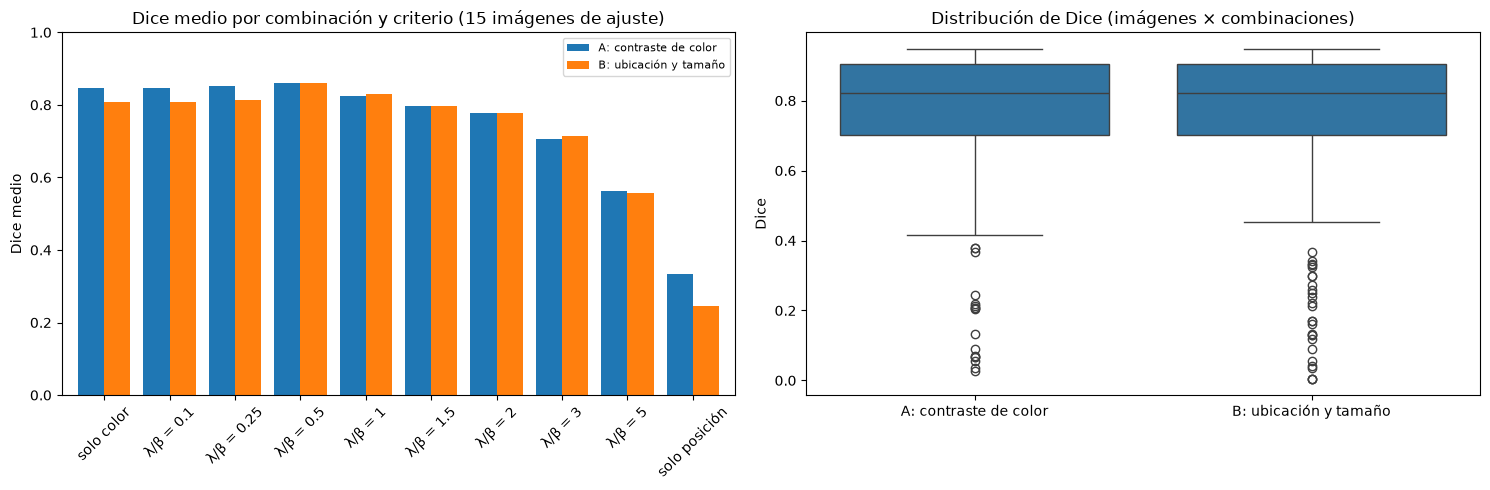

In [31]:
iou_comp = pd.DataFrame({n: res_criterios[n][1].mean(axis=0) for n in CRITERIOS})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

iou_comp.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Dice medio por combinación y criterio (15 imágenes de ajuste)")
axes[0].set_ylabel("Dice medio"); axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)

# Distribución por imagen (todas las combinaciones juntas)
datos = pd.concat([
    pd.DataFrame({"Dice": res_criterios[n][1].values.ravel(), "Criterio": n})
    for n in CRITERIOS])
sns.boxplot(data=datos, x="Criterio", y="Dice", ax=axes[1])
axes[1].set_title("Distribución de Dice (imágenes × combinaciones)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

### 3.5 Sensibilidad a los umbrales

El criterio A es poco sensible a su umbral relativo: el Dice medio es 0,740, 0,741 y 0,730 para 0,3, 0,5 y 0,7. El criterio B no cambia en absoluto con el umbral de la razón de borde, que da 0,721 en los tres valores. Sus grupos tienen una razón de borde muy separada, cerca de 0 los centrales y cerca de 1 los de piel, por lo que cualquier umbral intermedio produce la misma selección. Por eso se mantienen los valores 0,5.

In [32]:
print("Criterio A, umbral relativo de contraste:")
for u in [0.3, 0.5, 0.7]:
    m = evaluar_criterio(mascara_criterio_a, imgs_ajuste, masks_ajuste, umbral_a=u)[1]
    print(f"  umbral_a = {u}: Dice medio = {m.values.mean():.3f}")

print("Criterio B, umbral de razón de borde:")
for u in [0.25, 0.5, 0.75]:
    m = evaluar_criterio(mascara_criterio_b, imgs_ajuste, masks_ajuste, umbral_b=u)[1]
    print(f"  umbral_b = {u}: Dice medio = {m.values.mean():.3f}")

Criterio A, umbral relativo de contraste:
  umbral_a = 0.3: Dice medio = 0.740
  umbral_a = 0.5: Dice medio = 0.741
  umbral_a = 0.7: Dice medio = 0.730
Criterio B, umbral de razón de borde:
  umbral_b = 0.25: Dice medio = 0.721
  umbral_b = 0.5: Dice medio = 0.721
  umbral_b = 0.75: Dice medio = 0.721


### 3.6 Inspeccion visual

La inspección visual muestra, para la imagen 0 y la mejor combinación de cada criterio, los grupos, la máscara estimada y la referencia. Sirve para ver qué grupos selecciona cada criterio y cómo se relacionan con el borde real de la lesión.

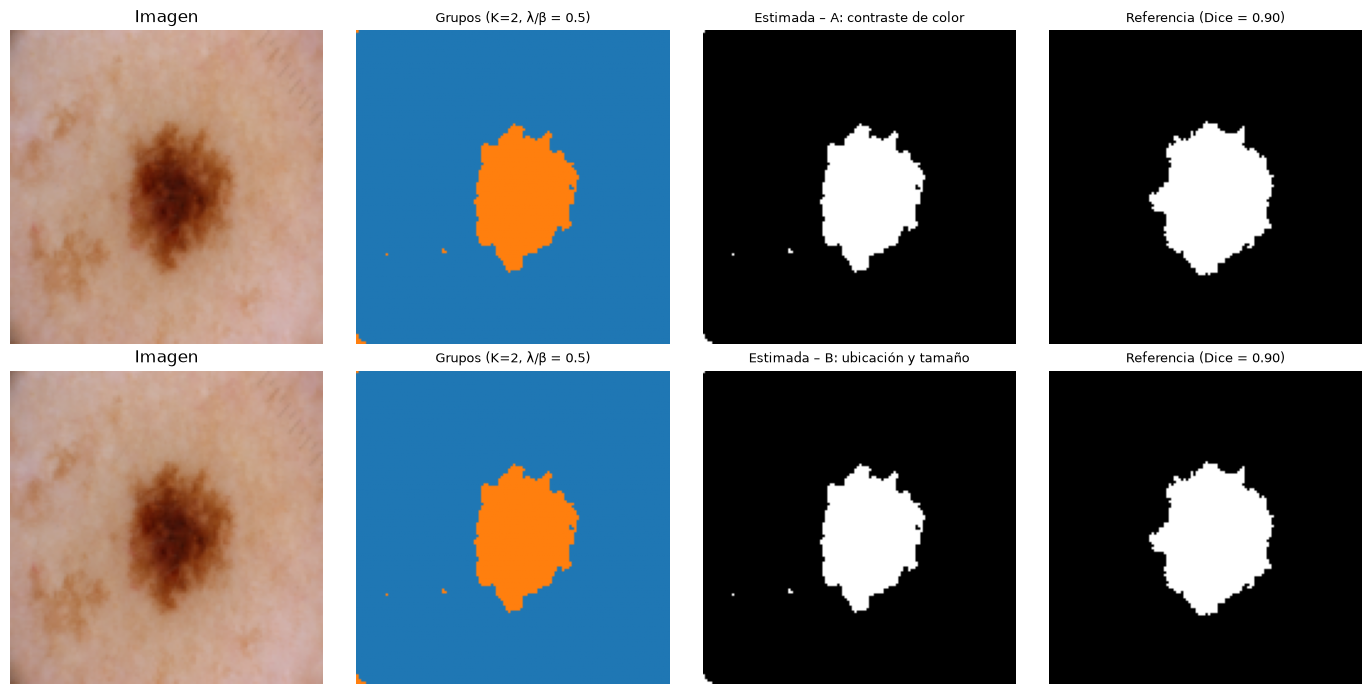

In [33]:
i = 0
dice_comp = pd.DataFrame({n: res_criterios[n][1].mean(axis=0) for n in CRITERIOS})
mejor_j = {n: int(dice_comp[n].values.argmax()) for n in CRITERIOS}

fig, axes = plt.subplots(len(CRITERIOS), 4, figsize=(14, 7))
for fila, (nombre, fn) in enumerate(CRITERIOS.items()):
    j = mejor_j[nombre]
    r = resultados[(i, j)]
    etq = r["etiquetas"][r["k_opt"]]
    est = fn(imgs_ajuste[i], etq)
    axes[fila, 0].imshow(imgs_ajuste[i]);                      axes[fila, 0].set_title("Imagen")
    axes[fila, 1].imshow(etq.reshape(TAMANO[1], TAMANO[0]), cmap="tab10", vmin=0, vmax=9)
    axes[fila, 1].set_title(f"Grupos (K={r['k_opt']}, {nombres_comb[j]})", fontsize=9)
    axes[fila, 2].imshow(est, cmap="gray");                    axes[fila, 2].set_title(f"Estimada – {nombre}", fontsize=9)
    axes[fila, 3].imshow(masks_ajuste[i], cmap="gray")
    axes[fila, 3].set_title(f"Referencia (Dice = {dice(est, masks_ajuste[i]):.2f})", fontsize=9)
    for ax in axes[fila]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Ajuste del método

La exploración usa solo las 15 imágenes de ajuste. Para cada combinación de β y λ y cada criterio de construcción de la máscara se calculan el Dice y el V-measure de cada imagen. El Dice promedio es el criterio principal para elegir la configuración y el V-measure es información complementaria.

### 4.1 Dice y V-measure por configuración

In [34]:
from sklearn.metrics import v_measure_score, precision_score, recall_score

filas = []
for nombre_criterio, fn in CRITERIOS.items():
    for j, c in enumerate(COMBINACIONES):
        for i, (img, ref) in enumerate(zip(imgs_ajuste, masks_ajuste)):
            r = resultados[(i, j)]
            etq = r["etiquetas"][r["k_opt"]]
            est = fn(img, etq)
            filas.append({
                "criterio": nombre_criterio,
                "combinacion": c["nombre"],
                "imagen": nombres_ajuste[i],
                "K": r["k_opt"],
                "silueta": r["siluetas"][r["k_opt"]],
                "dice": dice(est, ref),
                "v_measure": v_measure_score(ref.ravel(), etq),
            })
df_ajuste = pd.DataFrame(filas)

resumen_ajuste = (
    df_ajuste.groupby(["criterio", "combinacion"])
    .agg(dice_prom=("dice", "mean"), v_measure_prom=("v_measure", "mean"),
         K_prom=("K", "mean"), silueta_prom=("silueta", "mean"))
    .reset_index()
    .sort_values("dice_prom", ascending=False)
    .reset_index(drop=True)
)
display(resumen_ajuste.round(3))


,criterio,combinacion,dice_prom,v_measure_prom,K_prom,silueta_prom
0,A: contraste de color,λ/β = 0.5,0.861,0.526,3.200,0.493
1,B: ubicación y tamaño,λ/β = 0.5,0.861,0.526,3.200,0.493
2,A: contraste de color,λ/β = 0.25,0.852,0.612,2.200,0.617
3,A: contraste de color,solo color,0.847,0.642,2.000,0.750
4,A: contraste de color,λ/β = 0.1,0.847,0.642,2.000,0.717
5,B: ubicación y tamaño,λ/β = 1,0.829,0.302,5.067,0.438
6,A: contraste de color,λ/β = 1,0.825,0.302,5.067,0.438
7,B: ubicación y tamaño,λ/β = 0.25,0.813,0.612,2.200,0.617
8,B: ubicación y tamaño,solo color,0.807,0.642,2.000,0.750
9,B: ubicación y tamaño,λ/β = 0.1,0.807,0.642,2.000,0.717


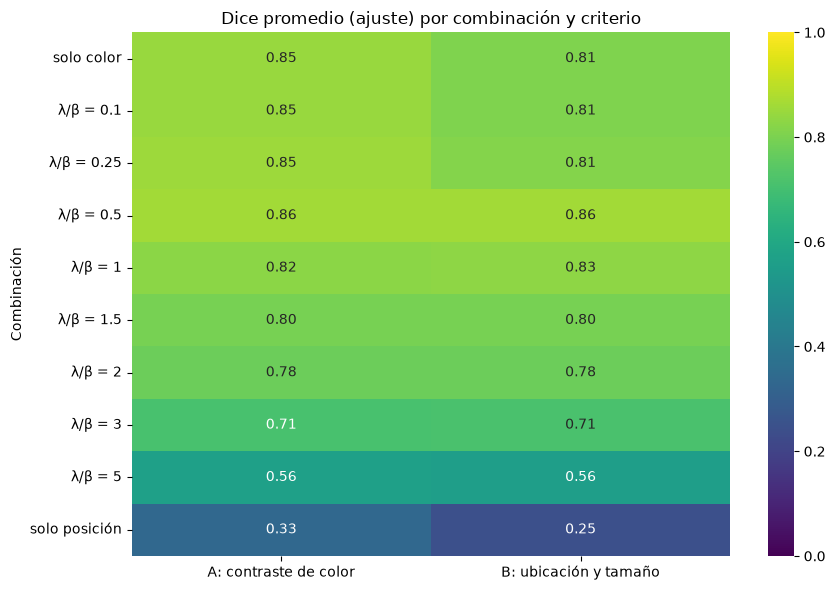

In [35]:
pivot = (df_ajuste.groupby(["combinacion", "criterio"])["dice"].mean()
         .unstack().reindex(nombres_comb))

plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Dice promedio (ajuste) por combinación y criterio")
plt.ylabel("Combinación"); plt.xlabel("")
plt.tight_layout(); plt.show()


Lectura de la tabla. La combinación λ/β = 0.5, con β = 1 y λ = 0.5, tiene el mayor Dice promedio con ambos criterios, 0.861. Las configuraciones de solo posición son las peores, con 0.335 y 0.246, porque dividen la imagen en regiones rectangulares que no siguen el borde de la lesión. Las de solo color, con 0.847, quedan cerca de las mejores, pero sin posición el método no tiene información espacial para separar la lesión de la piel con color parecido.

Los dos criterios empatan en λ/β = 0.5, 1.5 y 2. En el resto difieren menos de 0.05 en Dice promedio, salvo en solo posición, donde la diferencia es 0.089.

El V-measure más alto, 0.642, se da en solo color y en λ/β = 0.1, y no coincide con el Dice más alto. Una agrupación de la imagen puede corresponder bien a las etiquetas de referencia y aun así no producir una buena máscara de la lesión, que es lo que advierte el enunciado.

### 4.2 Casos de fallo de la mejor configuración

In [36]:
mejor = resumen_ajuste.iloc[0]
print(f"Mejor configuración por Dice promedio: {mejor.criterio} | {mejor.combinacion}")

casos = df_ajuste[(df_ajuste.criterio == mejor.criterio) &
                  (df_ajuste.combinacion == mejor.combinacion)].sort_values("dice")
display(casos.round(3))


Mejor configuración por Dice promedio: A: contraste de color | λ/β = 0.5


,criterio,combinacion,imagen,K,silueta,dice,v_measure
53,A: contraste de color,λ/β = 0.5,ISIC_0000133,2,0.451,0.740,0.426
50,A: contraste de color,λ/β = 0.5,ISIC_0000114,5,0.356,0.743,0.108
51,A: contraste de color,λ/β = 0.5,ISIC_0000116,5,0.456,0.746,0.286
59,A: contraste de color,λ/β = 0.5,ISIC_0000112,5,0.414,0.770,0.226
55,A: contraste de color,λ/β = 0.5,ISIC_0000150,2,0.495,0.819,0.570
58,A: contraste de color,λ/β = 0.5,ISIC_0000157,2,0.541,0.856,0.623
48,A: contraste de color,λ/β = 0.5,ISIC_0000094,5,0.399,0.883,0.207
52,A: contraste de color,λ/β = 0.5,ISIC_0000122,5,0.473,0.888,0.378
45,A: contraste de color,λ/β = 0.5,ISIC_0000085,2,0.533,0.903,0.760
49,A: contraste de color,λ/β = 0.5,ISIC_0000108,2,0.564,0.910,0.765


Casos de fallo de la mejor configuración. En el ajuste ninguna imagen cae por debajo de 0.74 de Dice. Las tres peores son ISIC_0000133 con 0.740, ISIC_0000114 con 0.743 e ISIC_0000116 con 0.746, y su silueta está entre 0.36 y 0.46 en el K elegido. En ajuste el método falla de forma moderada, no catastrófica.

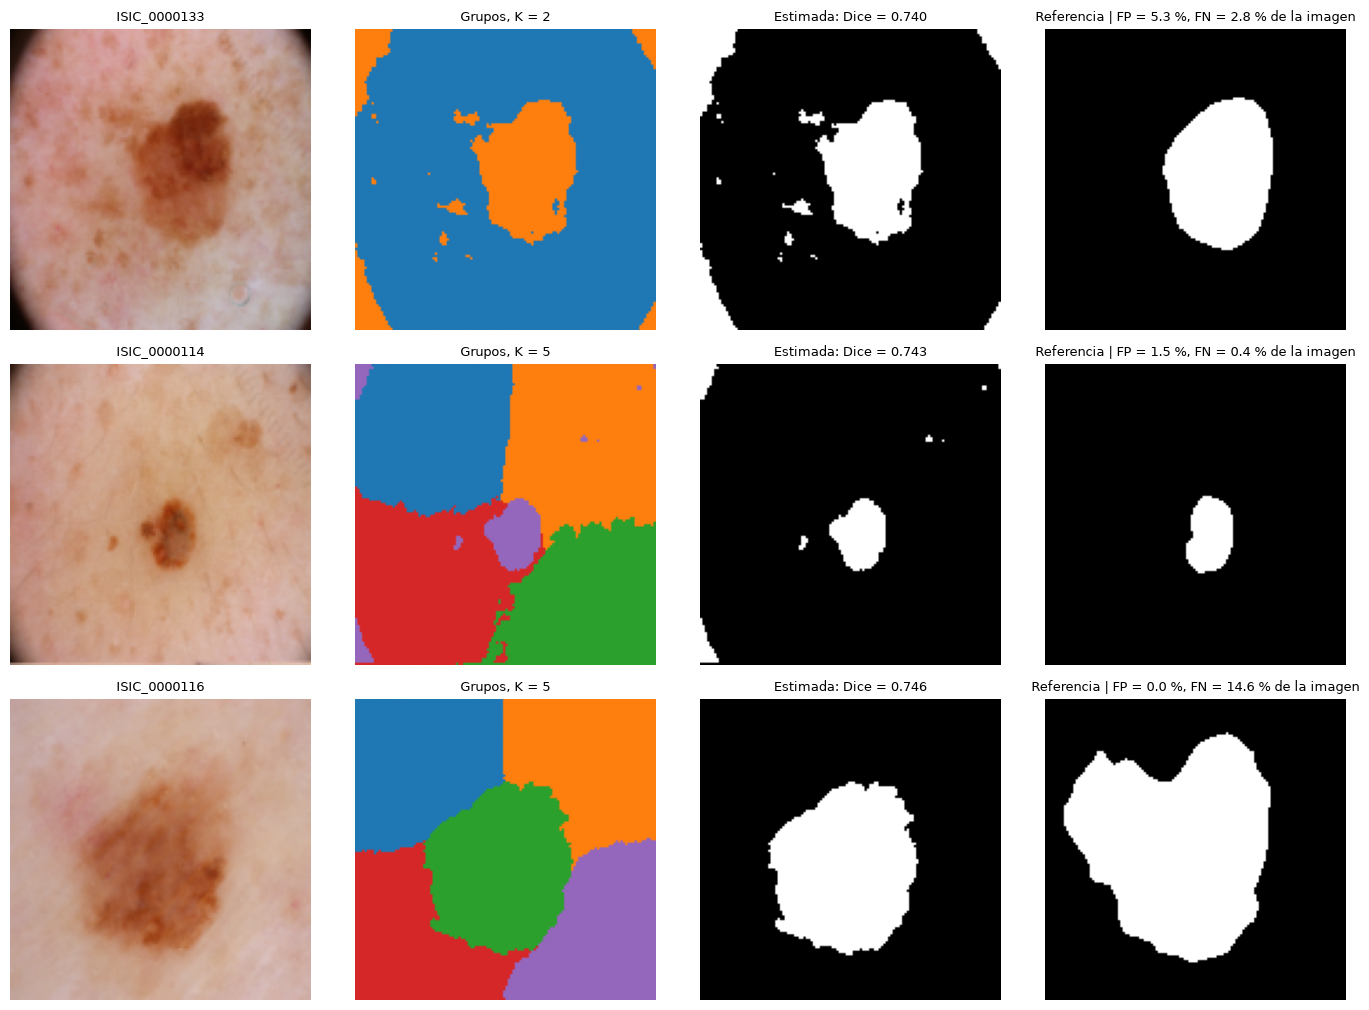

ISIC_0000133: lesión de referencia = 14.2 % de la imagen


,tamano,contraste,razon_borde,% en lesión (ref),seleccionado
grupo,,,,,
0,0.833,0.023,1.055,3.3,False
1,0.167,0.512,0.724,68.4,True


ISIC_0000114: lesión de referencia = 3.1 % de la imagen


,tamano,contraste,razon_borde,% en lesión (ref),seleccionado
grupo,,,,,
0,0.236,0.016,0.973,0.0,False
1,0.257,0.033,0.975,0.7,False
2,0.215,0.068,1.194,0.0,False
3,0.251,0.072,0.953,0.9,False
4,0.042,0.495,0.600,64.7,True


ISIC_0000116: lesión de referencia = 36.1 % de la imagen


,tamano,contraste,razon_borde,% en lesión (ref),seleccionado
grupo,,,,,
0,0.211,0.045,1.183,35.9,False
1,0.209,0.041,1.168,21.5,False
2,0.215,0.469,0.000,100.0,True
3,0.178,0.074,1.403,12.6,False
4,0.187,0.021,1.369,1.7,False


In [ ]:
# Evidencia para 4.2: las tres peores imágenes de ajuste con la configuración final
mejor_cfg = resumen_ajuste.iloc[0]                    # la misma configuración que se fija en 4.4
j_final = nombres_comb.index(mejor_cfg.combinacion)
fn_final = CRITERIOS[mejor_cfg.criterio]
peores = (df_ajuste[(df_ajuste.criterio == mejor_cfg.criterio) &
                    (df_ajuste.combinacion == mejor_cfg.combinacion)]
          .sort_values("dice").head(3)["imagen"].tolist())

fig, axes = plt.subplots(len(peores), 4, figsize=(14, 3.4 * len(peores)))
tablas_fallo = {}
for fila, nombre in enumerate(peores):
    i = nombres_ajuste.index(nombre)
    r = resultados[(i, j_final)]
    etq = r["etiquetas"][r["k_opt"]]
    est = fn_final(imgs_ajuste[i], etq)
    ref = masks_ajuste[i]
    fp = 100 * np.logical_and(est == 1, ref == 0).mean()
    fn = 100 * np.logical_and(est == 0, ref == 1).mean()

    axes[fila, 0].imshow(imgs_ajuste[i]);  axes[fila, 0].set_title(nombre, fontsize=9)
    axes[fila, 1].imshow(etq.reshape(TAMANO[1], TAMANO[0]), cmap="tab10", vmin=0, vmax=9)
    axes[fila, 1].set_title(f"Grupos, K = {r['k_opt']}", fontsize=9)
    axes[fila, 2].imshow(est, cmap="gray", vmin=0, vmax=1)
    axes[fila, 2].set_title(f"Estimada: Dice = {dice(est, ref):.3f}", fontsize=9)
    axes[fila, 3].imshow(ref, cmap="gray", vmin=0, vmax=1)
    axes[fila, 3].set_title(f"Referencia | FP = {fp:.1f} %, FN = {fn:.1f} % de la imagen", fontsize=9)
    for ax in axes[fila]:
        ax.axis("off")

    f = caracteristicas_grupos(imgs_ajuste[i], etq)
    f["% en lesión (ref)"] = [round(100 * ref.ravel()[etq == g].mean(), 1) for g in f.index]
    f["seleccionado"] = [bool(est.ravel()[etq == g].all()) for g in f.index]
    tablas_fallo[nombre] = f
plt.tight_layout()
plt.show()

for nombre, f in tablas_fallo.items():
    print(f"{nombre}: lesión de referencia = {100 * masks_ajuste[nombres_ajuste.index(nombre)].mean():.1f} % de la imagen")
    display(f.round(3))

Las tres peores imágenes de ajuste no fallan por lo mismo, y la figura de arriba lo muestra.

ISIC_0000133 tiene K = 2, pero el grupo elegido no contiene solo la lesión. Ocupa el 16.7 % de la imagen y apenas el 68.4 % de sus píxeles cae dentro de la referencia. Junto a la lesión arrastra las esquinas oscuras del viñeteado y varias manchas pigmentadas a la izquierda, que tienen un color parecido. Eso da 5.3 % de la imagen en falsos positivos, y además faltó el 2.8 %, cerca de una quinta parte de la lesión. El Dice queda en 0.740.

ISIC_0000114 es una lesión pequeña, el 3.1 % de la imagen, y ahí cualquier resto pesa mucho. El grupo elegido ocupa el 4.2 % y el 64.7 % de sus píxeles está en la referencia. Arrastra un trozo de la esquina inferior izquierda y unas manchas diminutas. Son solo 1.5 % de la imagen en falsos positivos, pero equivalen a casi la mitad del tamaño de la lesión, y por eso el Dice es 0.743. Con K = 5 la posición parte la piel en cuatro bloques y la lesión queda en un grupo pequeño.

ISIC_0000116 es el caso contrario. No hay falsos positivos, 0.0 %, pero se pierde el 14.6 % de la imagen, cerca del 40 % de la lesión. Es una lesión grande, el 36.1 % de la imagen, con un borde más claro. El grupo elegido es su núcleo, con contraste de 0.469 y el 100 % de sus píxeles dentro de la referencia. La periferia quedó repartida entre los grupos 0, 1 y 3, que son bloques de piel con 35.9 %, 21.5 % y 12.6 % de píxeles de lesión y contraste bajo, de 0.045, 0.041 y 0.074. Como el criterio A solo selecciona grupos de alto contraste, no los incluye. El Dice es 0.746.

Los tres casos apuntan a la misma debilidad por lados distintos. El criterio A decide por el contraste del color medio de cada grupo. Ese promedio mezcla la lesión con otras zonas oscuras, como pasa en 133 y 114, o deja fuera la parte de la lesión que se parece a la piel, como en 116. Con λ/β = 0.5 la posición agrava el segundo problema, porque parte la piel en bloques que cortan el borde de la lesión. Por eso elegimos esta configuración por su Dice promedio y no porque funcione bien en todos los casos. Sus errores vienen de la representación de color y posición y no de un umbral mal puesto.

### 4.3 Visualización de las configuraciones seleccionadas

Se muestran las dos configuraciones con mayor Dice promedio y las de solo color y solo posición, cada una con el criterio que mejor les fue.

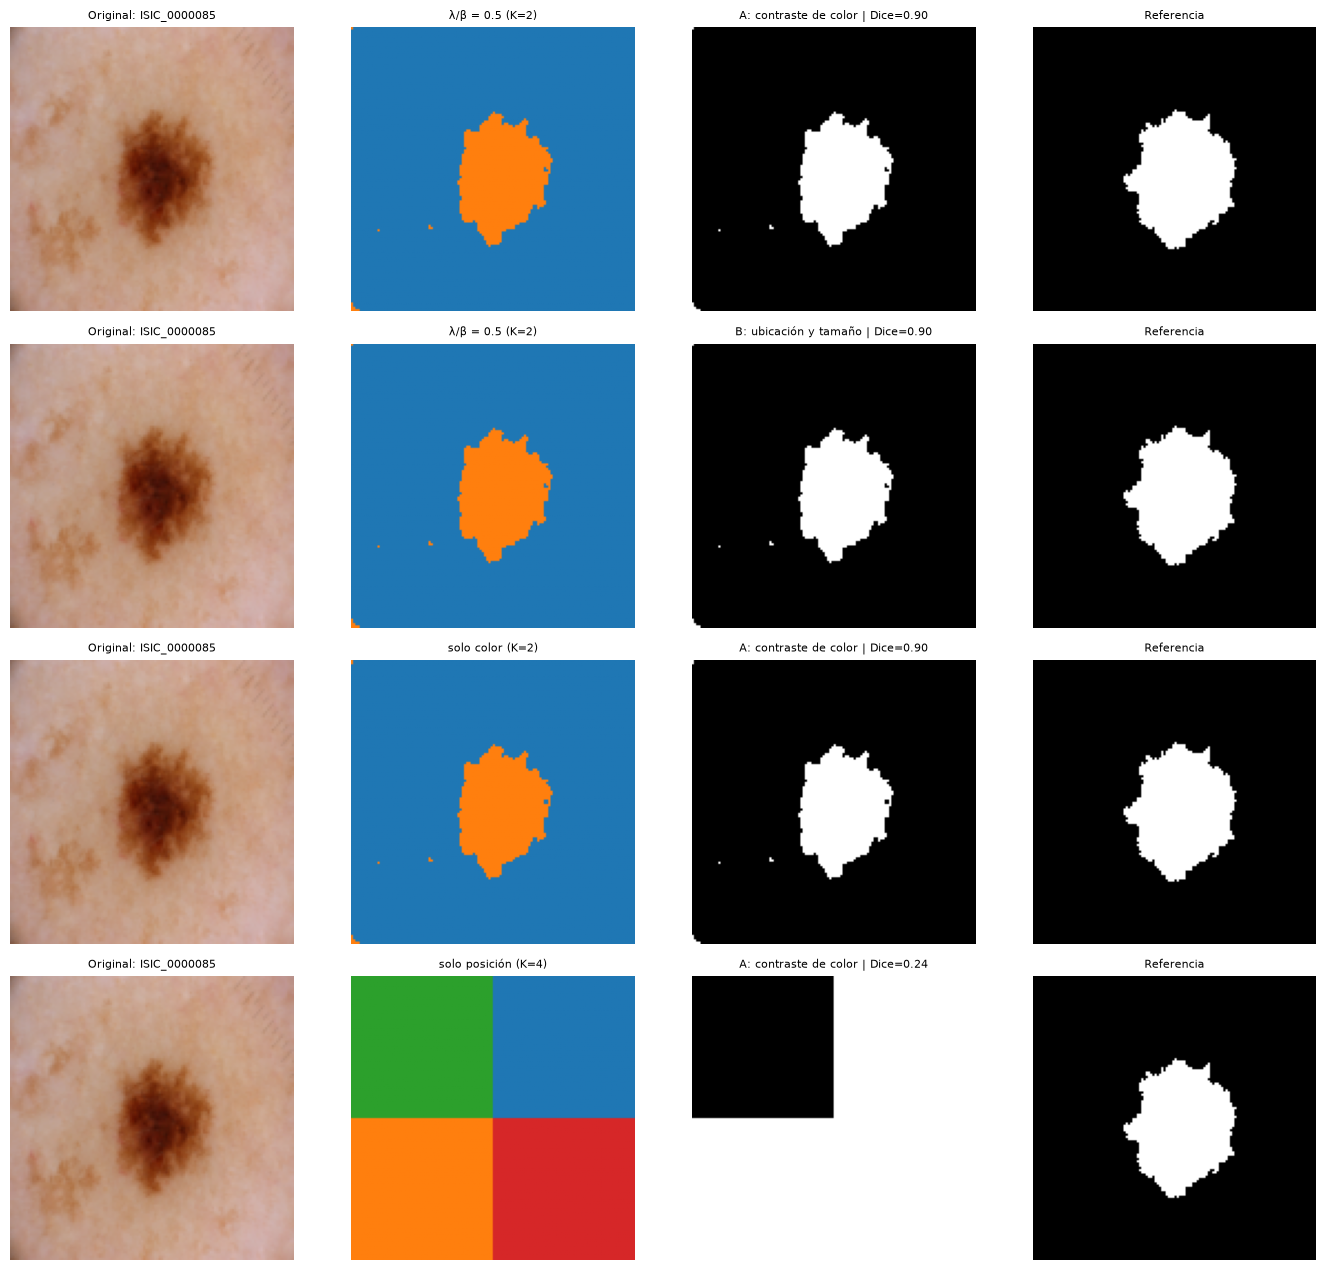

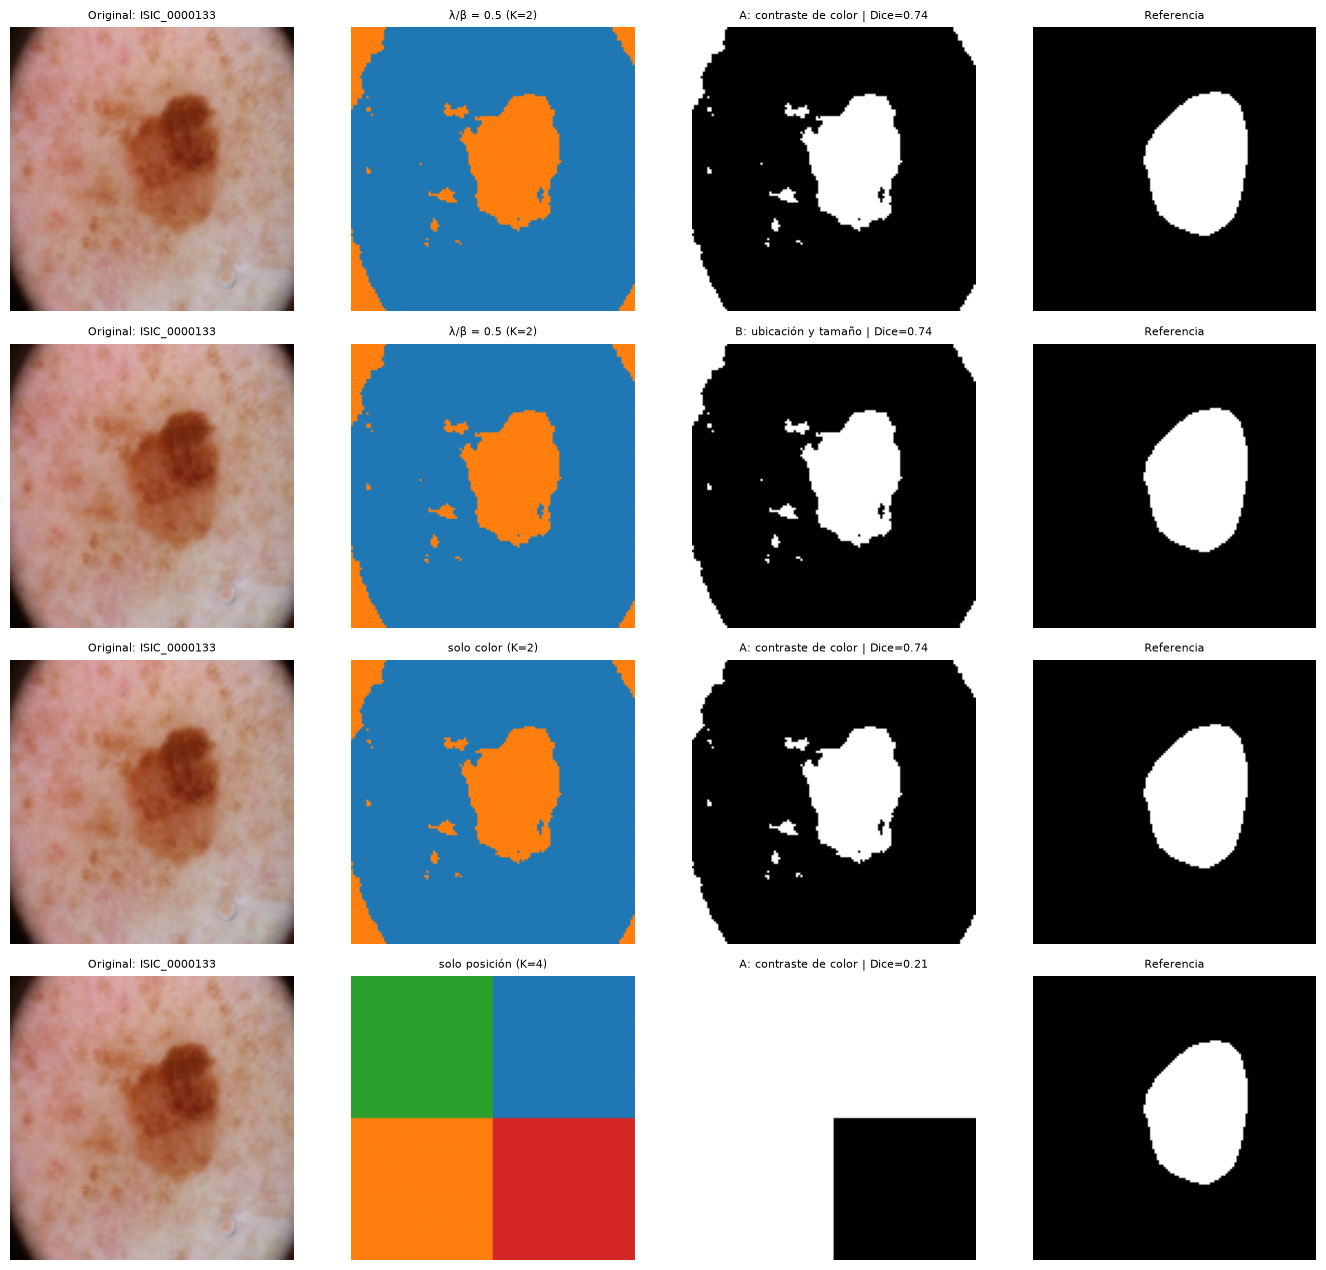

In [37]:
nombre_a_j = {c["nombre"]: j for j, c in enumerate(COMBINACIONES)}

def mejor_criterio_para(combinacion):
    return resumen_ajuste[resumen_ajuste.combinacion == combinacion].iloc[0].criterio

configs_vista = [
    (resumen_ajuste.iloc[0].criterio, resumen_ajuste.iloc[0].combinacion),
    (resumen_ajuste.iloc[1].criterio, resumen_ajuste.iloc[1].combinacion),
    (mejor_criterio_para("solo color"), "solo color"),
    (mejor_criterio_para("solo posición"), "solo posición"),
]

def dibujar_configuracion(axes, i, nombre_criterio, nombre_comb_v):
    j = nombre_a_j[nombre_comb_v]
    r = resultados[(i, j)]
    etq = r["etiquetas"][r["k_opt"]]
    est = CRITERIOS[nombre_criterio](imgs_ajuste[i], etq)
    axes[0].imshow(imgs_ajuste[i])
    axes[0].set_title(f"Original: {nombres_ajuste[i]}", fontsize=8)
    axes[1].imshow(etq.reshape(TAMANO[1], TAMANO[0]), cmap="tab10", vmin=0, vmax=9)
    axes[1].set_title(f"{nombre_comb_v} (K={r['k_opt']})", fontsize=8)
    axes[2].imshow(est, cmap="gray")
    axes[2].set_title(f"{nombre_criterio} | Dice={dice(est, masks_ajuste[i]):.2f}", fontsize=8)
    axes[3].imshow(masks_ajuste[i], cmap="gray")
    axes[3].set_title("Referencia", fontsize=8)
    for ax in axes:
        ax.axis("off")

# Imagen 0 y la imagen de peor Dice de la mejor configuración
i_peor = nombres_ajuste.index(casos.sort_values("dice").iloc[0].imagen)
for i_vista in [0, i_peor]:
    fig, axes = plt.subplots(len(configs_vista), 4, figsize=(14, 3.2 * len(configs_vista)))
    for fila, (crit, comb_v) in enumerate(configs_vista):
        dibujar_configuracion(axes[fila], i_vista, crit, comb_v)
    plt.tight_layout(); plt.show()


### 4.4 Configuración final

Se elige la configuración con mayor Dice promedio sobre las 15 imágenes de ajuste.

In [38]:
final = resumen_ajuste.iloc[0]
cfg_comb = next(c for c in COMBINACIONES if c["nombre"] == final.combinacion)

CONFIG_FINAL = {
    "criterio": final.criterio,
    "combinacion": final.combinacion,
    "beta": cfg_comb["beta"],
    "lam": cfg_comb["lam"],
}
FN_FINAL = CRITERIOS[CONFIG_FINAL["criterio"]]

print("Configuración final:", CONFIG_FINAL)
print(f"Dice promedio (ajuste): {final.dice_prom:.3f} | V-measure promedio (ajuste): {final.v_measure_prom:.3f}")


Configuración final: {'criterio': 'A: contraste de color', 'combinacion': 'λ/β = 0.5', 'beta': 1.0, 'lam': 0.5}
Dice promedio (ajuste): 0.861 | V-measure promedio (ajuste): 0.526


Selección. Por Dice promedio, λ/β = 0.5 es la mejor combinación. El criterio A y el B empatan en esa combinación, con 0.861 de Dice y 0.526 de V-measure, así que el empate no lo resuelve la métrica. Elegimos el criterio A porque usa una sola característica, el contraste de color con la piel, y no supone que la lesión esté alejada del borde, como sí hace el criterio B. La celda toma el primero de la tabla ordenada, y ese orden es el que define la configuración final.

## 5. Evaluación en imágenes de prueba

Se aplica la configuración final, sin cambios, a las 5 imágenes de prueba. Estas imágenes no se usaron para elegir β, λ, K ni el criterio de la máscara.

In [39]:
filas_prueba = []
resultados_prueba = {}
estimadas_prueba = {}
for img, ref, nombre in zip(imgs_prueba, masks_prueba, nombres_prueba):
    r = agrupar_imagen(img, CONFIG_FINAL["beta"], CONFIG_FINAL["lam"])
    etq = r["etiquetas"][r["k_opt"]]
    est = FN_FINAL(img, etq)
    resultados_prueba[nombre] = r
    estimadas_prueba[nombre] = est
    filas_prueba.append({
        "imagen": nombre,
        "K": r["k_opt"],
        "silueta": r["siluetas"][r["k_opt"]],
        "dice": dice(est, ref),
        "v_measure": v_measure_score(ref.ravel(), etq),
        "precision": precision_score(ref.ravel(), est.ravel(), zero_division=0),
        "recall": recall_score(ref.ravel(), est.ravel(), zero_division=0),
    })
tabla_prueba = pd.DataFrame(filas_prueba)
display(tabla_prueba.round(3))


,imagen,K,silueta,dice,v_measure,precision,recall
0,ISIC_0000087,2,0.496,0.882,0.641,0.997,0.791
1,ISIC_0000105,6,0.405,0.937,0.246,0.884,0.997
2,ISIC_0000110,6,0.388,0.000,0.180,0.000,0.000
3,ISIC_0000123,2,0.547,0.900,0.697,0.851,0.955
4,ISIC_0000128,2,0.541,0.933,0.818,1.000,0.874


Resultado en prueba. El Dice promedio baja de 0.861 en ajuste a 0.730 en prueba. Casi toda la caída viene de ISIC_0000110, que tiene Dice 0.00 y precisión y recall de 0. En esa imagen la lesión es pálida y tiene poco contraste con la piel, mientras que las esquinas oscuras por el viñeteado sí contrastan. El criterio A las selecciona, la máscara queda en el borde y no se superpone con la lesión.

Sin ISIC_0000110, el Dice promedio de las otras cuatro imágenes es 0.913, así que el método funciona bien en lesiones oscuras y con buen contraste, como ISIC_0000105, 0000123 y 0000128. En ISIC_0000105 la lesión se reparte en dos grupos dentro de K = 6 y la máscara incluye además una mancha pequeña fuera de la lesión, que es un falso positivo.

Este resultado no se usa para cambiar el método, porque el protocolo no lo permite. Se reporta tal cual y se analiza en la sección 5 del enunciado.

Dice promedio ajuste (15 imágenes): 0.861
Dice promedio prueba (5 imágenes):  0.730


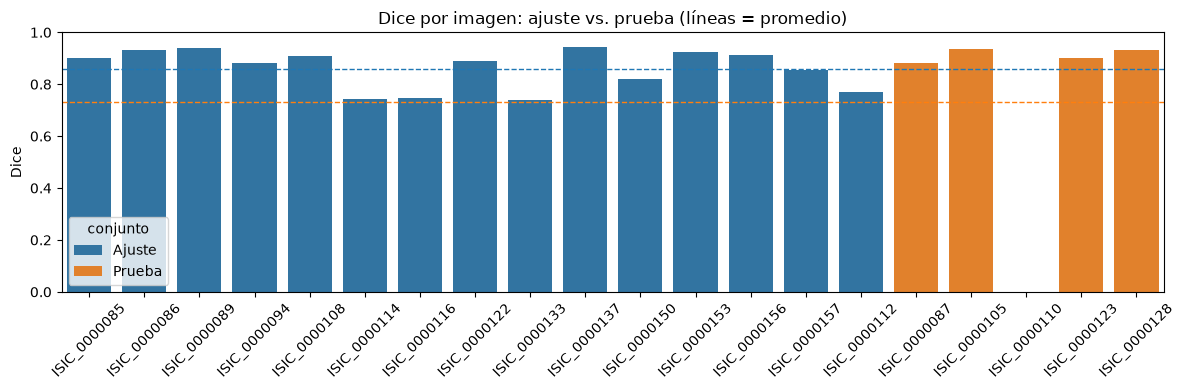

In [40]:
dice_ajuste_final = df_ajuste[(df_ajuste.criterio == CONFIG_FINAL["criterio"]) &
                              (df_ajuste.combinacion == CONFIG_FINAL["combinacion"])].dice.values

print(f"Dice promedio ajuste (15 imágenes): {dice_ajuste_final.mean():.3f}")
print(f"Dice promedio prueba (5 imágenes):  {tabla_prueba.dice.mean():.3f}")

comp = pd.concat([
    pd.DataFrame({"imagen": nombres_ajuste, "dice": dice_ajuste_final, "conjunto": "Ajuste"}),
    pd.DataFrame({"imagen": nombres_prueba, "dice": tabla_prueba.dice.values, "conjunto": "Prueba"}),
])
plt.figure(figsize=(12, 4))
sns.barplot(data=comp, x="imagen", y="dice", hue="conjunto")
plt.axhline(dice_ajuste_final.mean(), ls="--", color="tab:blue", lw=1)
plt.axhline(tabla_prueba.dice.mean(), ls="--", color="tab:orange", lw=1)
plt.ylim(0, 1); plt.ylabel("Dice"); plt.xlabel("")
plt.xticks(rotation=45); plt.title("Dice por imagen: ajuste vs. prueba (líneas = promedio)")
plt.tight_layout(); plt.show()


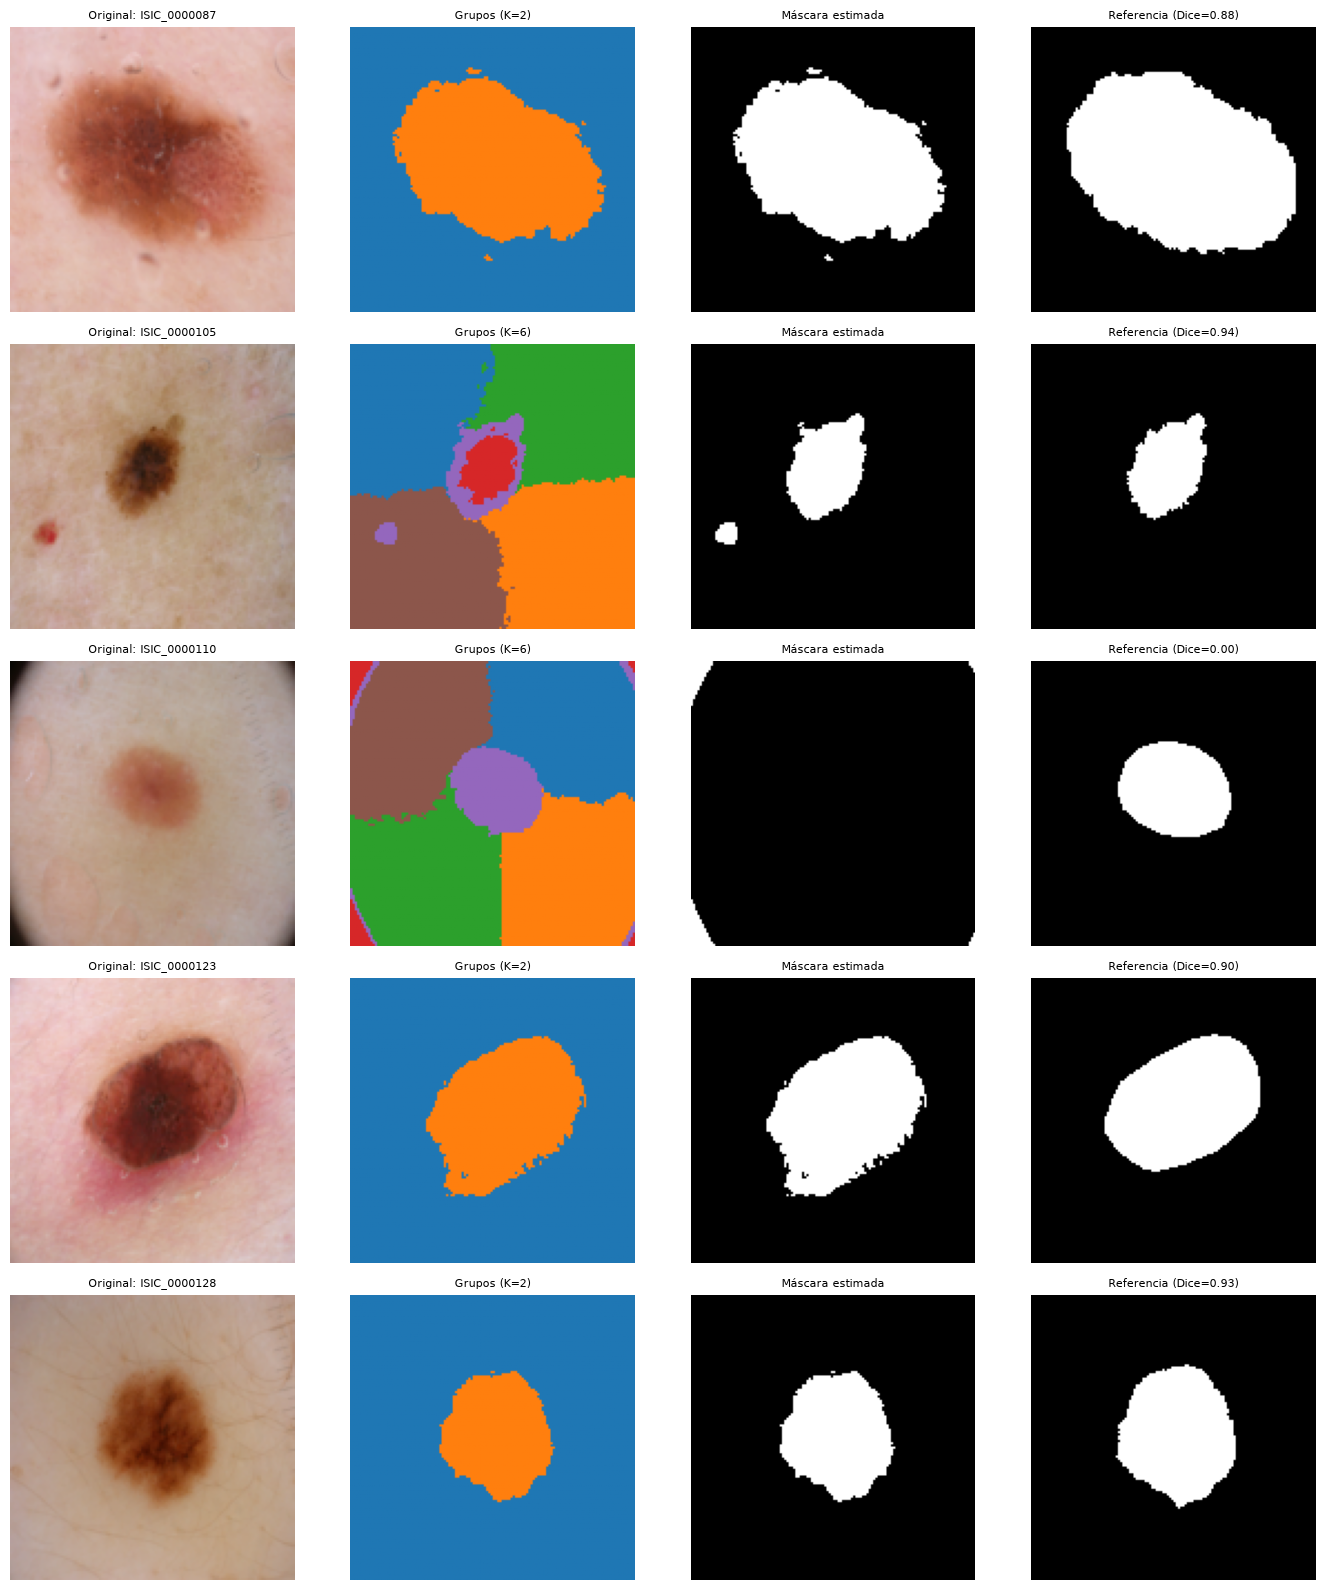

In [41]:
fig, axes = plt.subplots(len(nombres_prueba), 4, figsize=(14, 3.2 * len(nombres_prueba)))
for fila, (img, ref, nombre) in enumerate(zip(imgs_prueba, masks_prueba, nombres_prueba)):
    r = resultados_prueba[nombre]
    est = estimadas_prueba[nombre]
    axes[fila, 0].imshow(img); axes[fila, 0].set_title(f"Original: {nombre}", fontsize=8)
    axes[fila, 1].imshow(r["etiquetas"][r["k_opt"]].reshape(TAMANO[1], TAMANO[0]), cmap="tab10", vmin=0, vmax=9)
    axes[fila, 1].set_title(f"Grupos (K={r['k_opt']})", fontsize=8)
    axes[fila, 2].imshow(est, cmap="gray"); axes[fila, 2].set_title("Máscara estimada", fontsize=8)
    axes[fila, 3].imshow(ref, cmap="gray"); axes[fila, 3].set_title(f"Referencia (Dice={dice(est, ref):.2f})", fontsize=8)
    for ax in axes[fila]:
        ax.axis("off")
plt.tight_layout(); plt.show()


In [42]:
# Evidencia para el análisis: efecto de la posición (criterio fijo: A)
d_color = df_ajuste[(df_ajuste.criterio == "A: contraste de color") & (df_ajuste.combinacion == "solo color")].set_index("imagen")
d_mix = df_ajuste[(df_ajuste.criterio == "A: contraste de color") & (df_ajuste.combinacion == "λ/β = 0.5")].set_index("imagen")
efecto_pos = pd.DataFrame({
    "dice_solo_color": d_color.dice,
    "dice_lambda_beta_0.5": d_mix.dice,
    "dif (posición aporta)": d_mix.dice - d_color.dice,
    "K_solo_color": d_color.K,
    "K_lambda_beta_0.5": d_mix.K,
}).sort_values("dif (posición aporta)")
display(efecto_pos.round(3))
print(f"Imágenes donde la posición mejora: {(efecto_pos['dif (posición aporta)'] > 0.01).sum()}")
print(f"Imágenes donde la posición empeora: {(efecto_pos['dif (posición aporta)'] < -0.01).sum()}")
print(f"Imágenes sin cambio relevante (|dif| <= 0.01): {(efecto_pos['dif (posición aporta)'].abs() <= 0.01).sum()}")


,dice_solo_color,dice_lambda_beta_0.5,dif (posición aporta),K_solo_color,K_lambda_beta_0.5
imagen,,,,,
ISIC_0000116,0.760,0.746,-0.014,2,5
ISIC_0000122,0.902,0.888,-0.013,2,5
ISIC_0000153,0.934,0.924,-0.010,2,5
ISIC_0000133,0.743,0.740,-0.004,2,2
ISIC_0000150,0.821,0.819,-0.002,2,2
ISIC_0000157,0.858,0.856,-0.002,2,2
ISIC_0000156,0.912,0.912,-0.000,2,2
ISIC_0000089,0.940,0.940,0.000,2,2
ISIC_0000086,0.931,0.932,0.000,2,2


Imágenes donde la posición mejora: 3
Imágenes donde la posición empeora: 3
Imágenes sin cambio relevante (|dif| <= 0.01): 9


In [43]:
# Evidencia para el análisis: relación entre K, silueta y Dice
print("Correlación entre silueta promedio y Dice promedio (20 configuraciones):",
      round(resumen_ajuste[["silueta_prom", "dice_prom"]].corr().iloc[0, 1], 3))
print("Correlación entre K promedio y Dice promedio (20 configuraciones):",
      round(resumen_ajuste[["K_prom", "dice_prom"]].corr().iloc[0, 1], 3))

# Por imagen, para la configuración final
fin = df_ajuste[(df_ajuste.criterio == CONFIG_FINAL["criterio"]) &
                (df_ajuste.combinacion == CONFIG_FINAL["combinacion"])]
print("Correlación silueta-Dice por imagen (configuración final):",
      round(fin[["silueta", "dice"]].corr().iloc[0, 1], 3))

# Silueta más alta vs Dice más alto
mas_silueta = resumen_ajuste.sort_values("silueta_prom", ascending=False).iloc[0]
print(f"Mayor silueta promedio: {mas_silueta.combinacion} ({mas_silueta.criterio}) -> silueta {mas_silueta.silueta_prom:.3f}, Dice {mas_silueta.dice_prom:.3f}")
print(f"Mayor Dice promedio:    {final.combinacion} ({final.criterio}) -> silueta {final.silueta_prom:.3f}, Dice {final.dice_prom:.3f}")


Correlación entre silueta promedio y Dice promedio (20 configuraciones): 0.49
Correlación entre K promedio y Dice promedio (20 configuraciones): -0.283
Correlación silueta-Dice por imagen (configuración final): 0.63
Mayor silueta promedio: solo color (A: contraste de color) -> silueta 0.750, Dice 0.847
Mayor Dice promedio:    λ/β = 0.5 (A: contraste de color) -> silueta 0.493, Dice 0.861


In [44]:
# Evidencia para el análisis: falsos positivos y falsos negativos en prueba
fp_fn = []
for nombre in nombres_prueba:
    ref = masks_prueba[nombres_prueba.index(nombre)]
    est = estimadas_prueba[nombre]
    fp = int(np.logical_and(est == 1, ref == 0).sum())
    fn = int(np.logical_and(est == 0, ref == 1).sum())
    fp_fn.append({"imagen": nombre, "lesion_ref_%": round(100 * ref.mean(), 1),
                  "lesion_est_%": round(100 * est.mean(), 1),
                  "falsos_positivos_%": round(100 * fp / ref.size, 1),
                  "falsos_negativos_%": round(100 * fn / ref.size, 1)})
display(pd.DataFrame(fp_fn))


,imagen,lesion_ref_%,lesion_est_%,falsos_positivos_%,falsos_negativos_%
0,ISIC_0000087,38.4,30.5,0.1,8.0
1,ISIC_0000105,7.0,7.9,0.9,0.0
2,ISIC_0000110,10.5,1.5,1.5,10.5
3,ISIC_0000123,18.7,21.0,3.1,0.8
4,ISIC_0000128,15.0,13.1,0.0,1.9


In [ ]:
# Evidencia para la limitación 1: por qué el criterio A no selecciona la lesión de ISIC_0000110
nombre_110 = "ISIC_0000110"
k110 = resultados_prueba[nombre_110]["k_opt"]
etq110 = resultados_prueba[nombre_110]["etiquetas"][k110]
img110 = imgs_prueba[nombres_prueba.index(nombre_110)]
ref110 = masks_prueba[nombres_prueba.index(nombre_110)]

f110 = caracteristicas_grupos(img110, etq110)
# Solo como diagnóstico posterior, sin modificar el método: qué parte de cada grupo cae dentro de la lesión de referencia
f110["% en lesión (ref)"] = [round(100 * ref110.ravel()[etq110 == g].mean(), 1) for g in f110.index]
umbral_rel = 0.5 * f110["contraste"].max()
f110["seleccionado"] = (f110["contraste"] >= umbral_rel) & (f110["contraste"] >= 0.08)
f110.loc[f110["contraste"].idxmax(), "seleccionado"] = True
display(f110.round(3))
print(f"K = {k110} | contraste máximo: {f110['contraste'].max():.3f} | umbral relativo, 0.5 × máximo: {umbral_rel:.3f}")

,tamano,contraste,razon_borde,% en lesión (ref),seleccionado
grupo,,,,,
0,0.217,0.016,1.102,3.2,False
1,0.227,0.036,1.069,2.6,False
2,0.234,0.056,0.930,4.2,False
3,0.015,0.812,2.740,0.0,True
4,0.086,0.325,0.329,87.9,False
5,0.221,0.077,1.050,3.1,False


K = 6 | contraste máximo: 0.812 | umbral relativo, 0.5 × máximo: 0.406


## Analisis de resultados 

### 1. ¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué

Al comparar solo color con λ/β = 0,5, ambos con el criterio A, el Dice promedio en ajuste sube de 0,847 a 0,861. La mejora es pequeña en promedio, pero depende de la imagen. Mejora en ISIC_0000114, que pasa de 0,593 a 0,743, en ISIC_0000094, de 0,813 a 0,883, y en ISIC_0000112, de 0,740 a 0,770. Empeora levemente en ISIC_0000116, 122 y 153, alrededor de 0,01 menos, y el resto queda dentro de 0,01.

El efecto pasa por K. Con solo color la silueta elige K = 2 en todas las imágenes, y con λ/β = 0,5 elige K = 5 en seis de ellas: 114, 094, 112, 116, 122 y 153. Las imágenes que mejoran o empeoran son las que cambian de K. Las que mantienen K = 2 no cambian. Se ve en ISIC_0000085 y ISIC_0000133, donde las máscaras de ambas combinaciones son prácticamente idénticas, con Dice de 0,90 y 0,74.

El beneficio no crece con λ. El Dice baja a 0,825 con λ/β = 1, a 0,707 con λ/β = 3 y a 0,335 con solo posición. En ese último caso los grupos son cuatro cuadrantes sin relación con la lesión, como se ve en la figura 4.3, y el criterio A obtiene Dice de 0,24 en ISIC_0000085 y 0,21 en ISIC_0000133. La posición ayuda solo con un peso moderado.

### 2. ¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?

La relación es débil. Entre las 20 configuraciones, la correlación entre silueta promedio y Dice promedio es 0,49, y la que hay entre K promedio y Dice promedio es negativa, de magnitud 0,283. Por imagen, con la configuración final, la correlación entre silueta y Dice es 0,63. Por ejemplo, ISIC_0000089 tiene silueta 0,633 y Dice 0,940, mientras que ISIC_0000114 tiene silueta 0,356 y Dice 0,743.

Las métricas no llevan a la misma decisión porque miden cosas distintas. La silueta mide qué tan compactos y separados están los grupos, pero no sabe cuál es la lesión. La mayor silueta promedio corresponde a solo color, con 0,750 y Dice de 0,847, mientras que el mayor Dice corresponde a λ/β = 0,5, con silueta de 0,493 y Dice de 0,861. Además, la silueta no es comparable entre combinaciones, porque cada una define un espacio de características distinto. Con solo posición los grupos son compactos, pero el Dice es solo 0,335.

### 3. ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

El Dice promedio baja de 0,861 en ajuste a 0,730 en prueba. Casi toda la caída viene de ISIC_0000110, que tiene Dice 0,000. Las otras cuatro imágenes de prueba tienen Dice entre 0,882 y 0,937, con promedio 0,913, incluso mejor que en ajuste. En ajuste ninguna imagen bajó de 0,740, así que ISIC_0000110 es un tipo de falla que el ajuste no mostró.

El valor de ajuste es una estimación optimista, porque la configuración se eligió como la mejor de 20 sobre esas mismas 15 imágenes. Además, con solo 5 imágenes de prueba, una sola pesa el 20 % del promedio. No se puede concluir que el método empeora en promedio, pero sí que puede fallar por completo en casos nuevos.

No se debe modificar el método tras ver las máscaras de prueba, porque esas imágenes pasarían a ser parte del ajuste. El Dice dejaría de estimar el desempeño con imágenes nuevas y quedaría inflado sin que lo notemos. Además, el cambio estaría diseñado para arreglar una imagen concreta y no el problema general. Por eso el resultado se reporta tal cual y la falla se analiza como limitación.

### 4. Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

Limitación 1: bajo contraste y viñeteado. En ISIC_0000110 la lesión ocupa el 10,5 % de la imagen, pero la máscara estimada solo el 1,5 %, y corresponde a las esquinas oscuras del viñeteado. K-medias sí aisló la lesión en un grupo central, con K = 6 y color morado en la figura, así que el fallo está en la selección de grupos. El criterio A usa un umbral relativo al contraste máximo, y la celda de evidencia anterior muestra qué pasa con los seis grupos. El grupo 3 son las esquinas del viñeteado: ocupa el 1,5 % de la imagen, tiene contraste de 0,812, razón de borde de 2,74 y ningún píxel dentro de la lesión. El grupo 4 es la lesión: el 87,9 % de sus píxeles cae dentro de la máscara de referencia, ocupa el 8,6 % de la imagen y tiene contraste de 0,325 y razón de borde de 0,329. El criterio A exige al menos la mitad del contraste máximo, que es 0,406, y la lesión, pálida y de color cercano al de la piel, queda en 0,325, así que no se selecciona, mientras que las esquinas sí. El criterio B, que usa la ubicación, sí habría elegido el grupo 4, pero no cambiamos la configuración después de ver las imágenes de prueba, porque el protocolo no lo permite.

Limitación 2: lesiones heterogéneas, de borde gradual o grandes. K-medias forma grupos compactos, pero las lesiones reales son irregulares y de color no uniforme. En ISIC_0000105, con K = 6, la lesión se reparte en un núcleo rojo y un anillo morado, que el criterio A recoge. El falso positivo es una mancha roja pequeña de la piel que comparte grupo con el anillo por tener un color parecido. El color RGB no distingue estructuras distintas con tono similar.

### 5. En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?

Los falsos negativos son los más graves porque son silenciosos. Una máscara que subestima la lesión reduce el área y el diámetro medidos, puede ocultar bordes irregulares y hace que el dermatólogo, que mira la región resaltada, ignore parte de la lesión. En un centro pequeño sin segunda opinión local, esto puede retrasar una derivación o un seguimiento. En ISIC_0000110, el 10,5 % de la imagen era lesión y quedó sin cubrir.

Los falsos positivos sobrestiman el tamaño y pueden empujar una medida por encima de un umbral de decisión, generando derivaciones innecesarias. También distraen al especialista y le hacen perder tiempo, lo contrario del objetivo de la herramienta. Suelen notarse más fácilmente a simple vista. Para mitigar ambos, la máscara debe mostrarse solo como superposición sobre la imagen original, con la posibilidad de que el dermatólogo la corrija o la rechace, y con alertas cuando toque el borde o sea muy pequeña. Además, para medir en milímetros se necesita la escala del dermatoscopio, que se pierde al reducir las imágenes.

En cuanto a sesgos, el criterio A depende del contraste entre lesión y piel. En pieles más oscuras ese contraste puede ser menor o distinto, y el método quedaría peor calibrado. Conjuntos públicos como ISIC se reportan como poco diversos en este aspecto, y con 20 imágenes no podemos medir el desempeño por subgrupos. Tampoco están representadas las lesiones pálidas, poco pigmentadas o sin borde definido, ni las zonas con vello, uñas o piel acral.

Sobre la adquisición, el método supone que el borde de la imagen es piel y que el viñeteado es oscuro en las esquinas. Otros dermatoscopios, otra iluminación o resolución, burbujas, reglas, marcas de tinta o un encuadre distinto rompen esos supuestos. El personal de los centros de salud no es especialista, así que el encuadre y el enfoque serán más variables que en un conjunto curado. Antes de usarlo con pacientes, conviene validarlo en una muestra local etiquetada por dermatólogos y estratificada por tono de piel, dispositivo y tipo de lesión, manteniendo al especialista en la decisión final.

## Uso de herramientas de IA generativa

### 1. Declaración del uso

Usamos la IA generativa de dos maneras distintas.

Claude Code, con el modelo Claude Sonnet 5.5, nos apoyó durante el desarrollo. Leyó el enunciado, la rúbrica y el notebook para señalar qué pedían los puntos 4 y 5 y qué nos faltaba. Sugirió prompts para pedir ayuda puntual. Escribió la celda 2.2, que prueba la recomendación de la IAG sobre las imágenes de ajuste, y ayudó a redactar esta sección. Es ayuda conceptual, revisión y generación de código de verificación.

Para la actividad de verificación lanzamos desde Claude Code un agente Claude nuevo, sin acceso al notebook ni a los datos, y le hicimos cuatro consultas seguidas. Le pedimos que respondiera solo con texto.

### 2. Actividad de verificación: recomendación de una IAG antes de elegir la configuración final

#### 2.1 Prompts y respuestas

La consulta describió las imágenes, es decir, una lesión oscura y central sobre piel clara, esquinas oscuras por el viñeteado y algunos pelos, sin anexar ninguna y sin nombrar el conjunto de datos. Los cuatro prompts y las cuatro respuestas, textuales, están en el archivo `historial_IAG.md`, que se adjunta a la entrega.

Los prompts fueron estos:

1. El inicial describe las imágenes y la representación `[β·R, β·G, β·B, λ·x, λ·y]`, y pregunta qué β, λ y K usar y cómo decidir qué grupos son la lesión.
2. El segundo pide valores numéricos de β y λ, una regla única para K, umbrales concretos y la forma exacta de calcular cada característica de los grupos.
3. El tercero pregunta qué pasa si la lesión es pálida o si las esquinas del viñeteado contrastan más que la lesión.
4. El cuarto pregunta qué tan segura está de los valores sin haber visto las imágenes y qué habría que medir para comprobarlos.

La recomendación concreta, en la respuesta 2, fue esta. Usar β = 1 y λ = 0.25, es decir una razón λ/β de 0.25. Elegir K con la silueta entre 2 y 6, sobre una muestra de 5000 píxeles y con n_init = 10, tomando el K más pequeño cuya silueta llegue al menos al 95 % de la máxima. Antes de agrupar, quitar los pelos con un black-hat de 11×11 y umbral 10, rellenarlos y suavizar con una gaussiana de σ = 1.5, y excluir las esquinas oscuras, que son las de luminancia menor que 0.15 conectadas al borde.

Para cada grupo, tomar su mayor componente conexo y calcular el contraste con la piel, que es la mediana de la luminancia del borde menos la luminancia media del grupo, la fracción del perímetro de la imagen que toca, la distancia normalizada al centro y el tamaño. Un grupo es candidato si el contraste es al menos 0.08, el borde a lo sumo 0.15, la distancia a lo sumo 0.45 y el tamaño está entre 0.03 y 0.70. La lesión es el candidato de mayor contraste, más los candidatos con contraste de al menos 0.6 veces el máximo que estén en contacto con él. Después vienen la apertura con radio 3, el cierre con radio 7, el relleno de huecos y el componente conexo mayor. Si no hay candidatos, usa Otsu y, como último recurso, un círculo central.

En las respuestas 3 y 4 la IAG avisó de tres cosas: una lesión pálida rompería su criterio de contraste, los números eran "valores iniciales razonables" sin calibrar con nuestras imágenes, y la silueta "no mide si la segmentación es correcta".

#### 2.2 Prueba de la recomendación sobre las imágenes de ajuste

La celda siguiente aplica la recomendación tal como la dio la IAG a las 15 imágenes de ajuste. No usa las de prueba ni sus máscaras, y las máscaras de referencia solo sirven para calcular el Dice. Hay una desviación: OpenCV no está instalado, así que el inpainting de los pelos con `cv2.inpaint` lo sustituimos por un relleno con filtro de mediana. Al final hay una ablación para ver qué parte de la recomendación explica el resultado.

In [45]:
# Prueba de la recomendación de la IAG sobre las 15 imágenes de ajuste (no se usan las de prueba)
from scipy import ndimage as ndi

IAG = {"beta": 1.0, "lam": 0.25, "k_rango": range(2, 7), "muestra": 5000, "n_init": 10,
       "frac_sil": 0.95, "l_esquina": 0.15, "c_min": 0.08, "b_max": 0.15,
       "d_max": 0.45, "a_min": 0.03, "a_max": 0.70, "frac_c": 0.6}


def disco(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x * x + y * y <= r * r


def luminancia(rgb):
    return 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]


def quitar_pelos(img):
    """Black-hat 11x11 sobre la luminancia (umbral 10) y relleno con mediana 7x7
    (sustituye a cv2.inpaint, que no está instalado), seguido de suavizado gaussiano (σ = 1.5)."""
    gris = luminancia(img.astype(np.float64))
    yy, xx = np.ogrid[-5:6, -5:6]
    el = (xx / 5.5) ** 2 + (yy / 5.5) ** 2 <= 1
    pelos = ndi.binary_dilation((ndi.grey_closing(gris, footprint=el) - gris) > 10, structure=disco(1))
    out = img.astype(np.float64)
    for c in range(3):
        out[..., c] = np.where(pelos, ndi.median_filter(out[..., c], size=7), out[..., c])
    out = np.stack([ndi.gaussian_filter(out[..., c], 1.5) for c in range(3)], axis=-1)
    return out / 255.0


def mascara_esquinas(L, umbral=IAG["l_esquina"]):
    oscuro = L < umbral
    lab, _ = ndi.label(oscuro)
    borde = np.zeros_like(oscuro)
    borde[0, :] = borde[-1, :] = borde[:, 0] = borde[:, -1] = True
    ids = np.unique(lab[borde & oscuro]); ids = ids[ids > 0]
    esq = np.isin(lab, ids)
    return np.zeros_like(esq) if esq.mean() > 0.30 else esq


def umbral_otsu(v):
    hist, bordes = np.histogram(v, bins=256, range=(0, 1))
    p = hist / hist.sum(); w0 = np.cumsum(p); mu = np.cumsum(p * np.arange(256))
    den = w0 * (1 - w0)
    sb = np.where(den > 0, (mu[-1] * w0 - mu) ** 2 / np.where(den > 0, den, 1), 0)
    return bordes[np.argmax(sb)] + 1 / 512


def limpiar_mascara(m):
    m = ndi.binary_fill_holes(ndi.binary_closing(ndi.binary_opening(m, structure=disco(3)), structure=disco(7)))
    lab, n = ndi.label(m)
    if n == 0:
        return m
    return lab == (1 + int(np.argmax(ndi.sum(m, lab, range(1, n + 1)))))


def segmentar_iag(img, lam=IAG["lam"], con_pelos=True, con_limpieza=True):
    rgb = quitar_pelos(img) if con_pelos else img.astype(np.float64) / 255.0
    h, w, _ = rgb.shape
    L = luminancia(rgb)
    esq = mascara_esquinas(L)
    valido = ~esq

    xx, yy = np.meshgrid(np.linspace(0, 1, w), np.linspace(0, 1, h))
    X = np.column_stack([IAG["beta"] * rgb.reshape(-1, 3), lam * xx.ravel(), lam * yy.ravel()])
    idx_val = np.flatnonzero(valido.ravel())
    Xv = X[idx_val]

    rng = np.random.default_rng(SEMILLA)
    idx_m = np.sort(rng.choice(len(idx_val), size=min(IAG["muestra"], len(idx_val)), replace=False))
    sil, etqs = {}, {}
    for k in IAG["k_rango"]:
        etqs[k] = KMeans(n_clusters=k, n_init=IAG["n_init"], random_state=SEMILLA).fit(Xv).labels_
        em = etqs[k][idx_m]
        sil[k] = silhouette_score(Xv[idx_m], em) if len(np.unique(em)) > 1 else -1
    k_sel = min(k for k in IAG["k_rango"] if sil[k] >= IAG["frac_sil"] * max(sil.values()))

    etq = -np.ones(h * w, dtype=int)
    etq[idx_val] = etqs[k_sel]
    etq = etq.reshape(h, w)

    borde = np.zeros((h, w), bool)
    borde[0, :] = borde[-1, :] = borde[:, 0] = borde[:, -1] = True
    ref = borde & valido
    L_piel = np.median(L[ref]) if ref.any() else np.median(L)

    cand = []
    for g in range(k_sel):
        lab, n = ndi.label(etq == g)
        if n == 0:
            continue
        comp = lab == (1 + int(np.argmax(ndi.sum(etq == g, lab, range(1, n + 1)))))
        A = comp.mean()
        if A < 0.01:
            continue
        B = (comp[0].sum() + comp[-1].sum() + comp[1:-1, 0].sum() + comp[1:-1, -1].sum()) / (2 * w + 2 * h - 4)
        cy, cx = np.argwhere(comp).mean(axis=0)
        d = np.sqrt(((cx - w / 2) / w) ** 2 + ((cy - h / 2) / h) ** 2) / np.sqrt(0.5)
        cand.append({"comp": comp, "C": L_piel - L[comp].mean(), "B": B, "d": d, "A": A})

    ok = [c for c in cand if c["C"] >= IAG["c_min"] and c["B"] <= IAG["b_max"]
          and c["d"] <= IAG["d_max"] and IAG["a_min"] <= c["A"] <= IAG["a_max"]]
    limpiar = limpiar_mascara if con_limpieza else (lambda m: m)
    respaldo = "ninguno"
    if ok:
        mejor = max(ok, key=lambda c: c["C"])
        mask = mejor["comp"].copy()
        dil = ndi.binary_dilation(mask, structure=disco(3))
        for c in ok:
            if c is not mejor and c["C"] >= IAG["frac_c"] * mejor["C"] and (dil & c["comp"]).any():
                mask |= c["comp"]
        mask = limpiar(mask)
    else:
        mask = limpiar((L < umbral_otsu(L[valido])) & valido)
        respaldo = "otsu"
        if not (0.03 <= mask.mean() <= 0.70):
            y2, x2 = np.ogrid[:h, :w]
            mask = (x2 - w / 2) ** 2 + (y2 - h / 2) ** 2 <= (0.25 * min(h, w)) ** 2
            respaldo = "círculo central"
    return (mask & valido).astype(np.uint8), k_sel, sil[k_sel], respaldo, esq.mean()


filas = []
for nombre, img, ref in zip(nombres_ajuste, imgs_ajuste, masks_ajuste):
    est, k, s, resp, frac_esq = segmentar_iag(img)
    filas.append({"imagen": nombre, "K": k, "silueta": round(s, 3), "dice": round(dice(est, ref), 3),
                  "respaldo": resp, "esquinas_excluidas": round(frac_esq, 2)})
tabla_iag = pd.DataFrame(filas).set_index("imagen")
display(tabla_iag)

dice_iag = tabla_iag["dice"].mean()
print(f"Dice promedio de la recomendación de la IAG (15 imágenes de ajuste): {dice_iag:.3f}")
print(f"Dice promedio de nuestra configuración final (λ/β = 0.5, criterio A):  {final.dice_prom:.3f}")
print(f"Mediana IAG: {tabla_iag['dice'].median():.3f} | mínimo IAG: {tabla_iag['dice'].min():.3f}")
print("K elegido por la IAG:", tabla_iag["K"].value_counts().sort_index().to_dict())

# Ablación: qué parte de la recomendación explica el resultado
variantes = {
    "Recomendación completa": dict(),
    "Sin limpieza morfológica": dict(con_limpieza=False),
    "Sin quitar pelos ni suavizado": dict(con_pelos=False),
    "λ = 0 (solo color)": dict(lam=0.0),
    "λ = 0.5": dict(lam=0.5),
}
ablacion = {nombre: np.mean([dice(segmentar_iag(img, **kw)[0], ref)
                             for img, ref in zip(imgs_ajuste, masks_ajuste)])
            for nombre, kw in variantes.items()}
display(pd.Series(ablacion, name="Dice promedio").round(3).to_frame())

,K,silueta,dice,respaldo,esquinas_excluidas
imagen,,,,,
ISIC_0000085,2,0.687,0.901,ninguno,0.00
ISIC_0000086,2,0.651,0.933,ninguno,0.00
ISIC_0000089,2,0.751,0.945,ninguno,0.00
ISIC_0000094,4,0.374,0.932,ninguno,0.00
ISIC_0000108,2,0.705,0.899,ninguno,0.00
ISIC_0000114,2,0.567,0.881,ninguno,0.00
ISIC_0000116,2,0.600,0.766,ninguno,0.00
ISIC_0000122,2,0.563,0.904,ninguno,0.00
ISIC_0000133,2,0.576,0.908,ninguno,0.01


Dice promedio de la recomendación de la IAG (15 imágenes de ajuste): 0.891
Dice promedio de nuestra configuración final (λ/β = 0.5, criterio A):  0.861
Mediana IAG: 0.904 | mínimo IAG: 0.766
K elegido por la IAG: {2: 14, 4: 1}


,Dice promedio
Recomendación completa,0.891
Sin limpieza morfológica,0.889
Sin quitar pelos ni suavizado,0.888
λ = 0 (solo color),0.889
λ = 0.5,0.882


#### 2.3 Análisis

¿Funcionó la recomendación en nuestras imágenes? 
En ajuste, sí. Su Dice promedio fue 0.891, contra 0.861 de nuestra configuración final, que usa λ/β = 0.5 y el criterio A. La mediana fue 0.904 y el peor caso 0.766. Eligió K = 2 en 14 de las 15 imágenes y K = 4 en una. Con solo 15 imágenes, 0.03 de diferencia no es mucho, y en ISIC_0000150 le fue algo peor que a nosotros, con 0.805 contra 0.819. Hay además un sesgo a favor de nuestro número: el 0.861 es el mejor de 20 configuraciones probadas sobre estas mismas imágenes, mientras que el 0.891 sale de una sola configuración sin selección.

Acertó en la estructura general. El color pesa más que la posición, K es pequeño, el contraste se mide contra la piel del borde y se descartan los grupos que tocan el borde. La ablación muestra dónde está el efecto. Quitar la limpieza morfológica deja el Dice en 0.889 y quitar el filtrado de pelos en 0.888, casi sin cambio, y λ = 0 da 0.889 y λ = 0.5 da 0.882, que tampoco mueven mucho el resultado. La ganancia parece venir de la regla de K y de la selección de grupos. Con λ/β = 0.5 nuestro método eligió K = 5 en seis imágenes, y nuestros cuatro peores Dice quedaron entre 0.740 y 0.770. Fueron ISIC_0000133 con K = 2 e ISIC_0000114, 116 y 112 con K = 5. La IAG, con K = 2, subió ISIC_0000133 a 0.908 y ISIC_0000114 a 0.881.

También hay cosas que fallaron o que no pudimos comprobar. Sus peores casos fueron ISIC_0000116 con 0.766, ISIC_0000112 con 0.801 e ISIC_0000150 con 0.805. Los dos primeros también estuvieron entre nuestros peores, con 0.746 y 0.770, lo que sugiere que son difíciles para cualquier método que use solo color y posición. Su regla de K, el más pequeño con silueta de al menos 0.95 de la máxima entre 2 y 6, no es la del enunciado, que pide la silueta máxima entre 2 y 8. Mejora el Dice, pero ya no se deriva directamente de la silueta. Además, el viñeteado y las lesiones pálidas casi no aparecen en ajuste. La máscara de esquinas excluyó como mucho el 1 % de los píxeles y el respaldo con Otsu nunca se activó, así que esas partes de la recomendación quedaron sin probar. Por último, los umbrales 0.08, 0.15, 0.45, 0.03 y 0.70 son valores de partida que la IAG no calibró, como ella misma admitió en la respuesta 4.

¿Por qué no podía anticipar el comportamiento del método en nuestras imágenes?
No vio las imágenes ni las máscaras, y el Dice depende de cómo los dermatólogos trazaron el borde de cada lesión, algo que el conocimiento general no predice. Los umbrales de contraste y de tamaño dependen de la resolución, que aquí es de 128 × 128, del dispositivo y de la iluminación. Tampoco conocía nuestro protocolo, que usa diez combinaciones de β y λ, K entre 2 y 8 elegido con la silueta y 15 imágenes de ajuste. Y la silueta mide qué tan compactos son los grupos, no qué tan bien coinciden con la lesión, así que ni ella ni nosotros podíamos saber sin medirlo qué K daría un buen Dice.

Decisión sobre la configuración final: mantenemos la del punto 4, con λ/β = 0.5 y criterio A. Esta verificación la hicimos después de fijarla y de evaluar las imágenes de prueba, no antes, como pide el enunciado. Cambiarla ahora, con el Dice de prueba ya conocido, que es 0.730, rompería la separación entre ajuste y prueba. La recomendación queda como comparación sobre las imágenes de ajuste y como pista para mejorar: limitar K y exigir que el grupo elegido no toque el borde.

### 3. Prompts principales usados con Claude Code

1. Leer el enunciado, la rúbrica y el notebook, y decir qué pedían exactamente los puntos 4 y 5 y qué faltaba, sin modificar código existente sin avisar.
2. Dar prompts de ejemplo para pedir ayuda puntual mientras se escribe el código, y luego versiones más cortas y sin nombres de variables.
3. Completar esta sección con esos prompts y hacer la consulta a una IA desde cero para la actividad de verificación, que son los cuatro prompts de la sección 2.1.
4. Terminar lo que faltaba de la sección y probar la recomendación sobre las imágenes de ajuste en la celda 2.2.

### 4. Análisis crítico del resultado

Lo útil fue la estructura de la recomendación: color dominante, K pequeño, comparar con la piel del borde y descartar grupos que tocan el borde. Mejoró el Dice de imágenes donde nuestro método quedaba bajo, como ISIC_0000133, que pasó de 0.740 a 0.908, e ISIC_0000114, que pasó de 0.743 a 0.881. Su advertencia sobre la silueta coincide con lo que vimos en el notebook.

Lo que falló o quedó corto: los valores exactos no estaban calibrados, preprocesar pelos y viñeteado aportó poco en estas imágenes, solo 0.003 y 0.002 de Dice, el inpainting con OpenCV no se pudo usar tal cual y la regla de K se aparta del enunciado.

Respecto a la IAG, mantuvimos nuestra regla de K, que es la silueta máxima entre 2 y 8, y la configuración final del punto 4, y cambiamos `cv2.inpaint` por un filtro de mediana. Hicimos la ablación para no tomar el Dice total como prueba de que toda la recomendación funciona.

Los conceptos del curso que nos sirvieron para evaluarla fueron tres. La silueta mide compacidad y el Dice mide coincidencia con la referencia. La configuración se elige solo con las imágenes de ajuste. Y escoger el máximo entre muchas configuraciones probadas sobre los mismos datos da un número optimista.

### 5. Aportes propios

La mayor parte del código del notebook lo escribimos nosotros a mano, es decir, el pipeline de representación, la agrupación y la selección de K, los criterios de construcción de la máscara, el ajuste y la evaluación. También tomamos las decisiones de diseño: las diez combinaciones de β y λ, los criterios A y B, la configuración final y las respuestas del análisis.

Claude Code nos ayudó a revisar el notebook frente al enunciado, a armar los prompts y a escribir la celda 2.2. La configuración final del punto 4 se mantuvo sin cambios.

Lo que aprendimos: una recomendación general puede acertar en la estructura y aun así necesitar calibración con datos propios, el Dice y la silueta responden preguntas distintas, y para comparar métodos hay que separar qué componentes explican la diferencia.

## Bonos

Esta sección reúne los dos bonos opcionales. Ambos usan la imagen ISIC_0000114 del conjunto de ajuste y la configuración final del laboratorio, con β = 1 y λ = 0.5. Las imágenes de prueba no se usan.

### Bono A. Visualización del espacio de representación

Elegimos ISIC_0000114, que con la configuración final queda con K = 5 grupos. Aplicamos PCA a una muestra de 3000 píxeles, con semilla 42, sobre la representación `[β·R, β·G, β·B, λ·x, λ·y]` y proyectamos a dos componentes. Hacemos dos visualizaciones de la misma proyección, una coloreada por grupo de K-medias y otra por la máscara de referencia.

Imagen: ISIC_0000114 | β = 1.0, λ = 0.5 | K = 5 | muestra de 3000 píxeles, semilla 42
Varianza explicada por PC1 y PC2: [0.407 0.355] | acumulada: 0.762


,β·R,β·G,β·B,λ·x,λ·y
PC1,0.22,0.34,0.36,0.83,0.15
PC2,0.01,-0.03,-0.01,-0.16,0.99


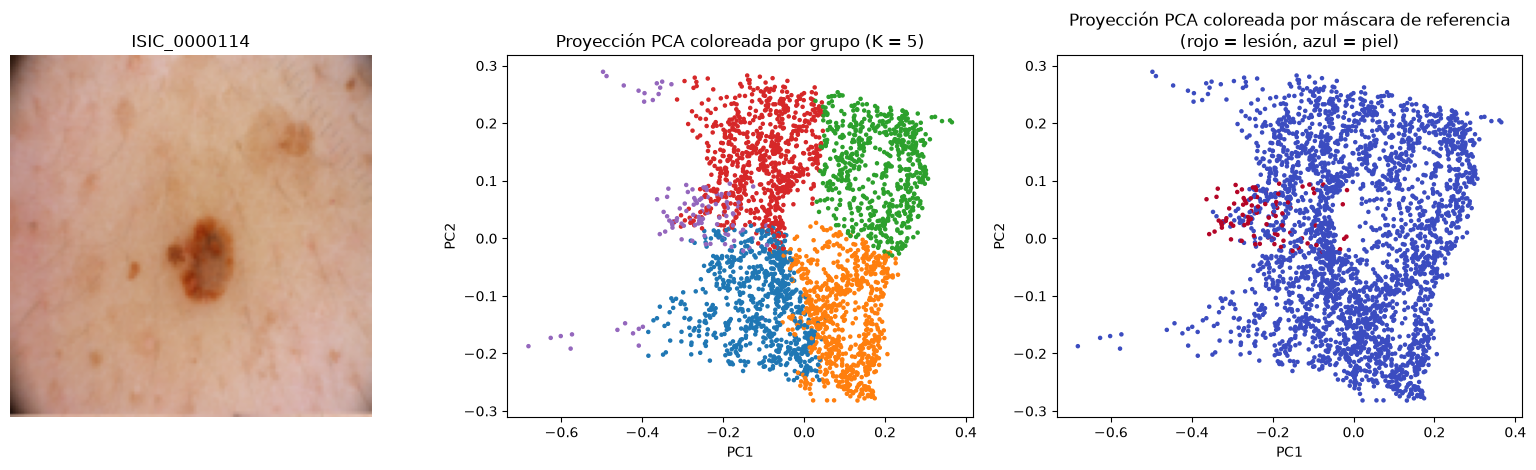

V-measure entre grupos y máscara de referencia (muestra): 0.106


referencia,lesión,piel,% lesión
grupo,,,
0,0,717,0.0
1,6,763,0.8
2,0,630,0.0
3,7,760,0.9
4,78,39,66.7


In [ ]:
# Bono A. PCA sobre una muestra de píxeles de una imagen de ajuste
from sklearn.decomposition import PCA
from sklearn.metrics import v_measure_score

NOMBRE_BONO = "ISIC_0000114"
i_bono = nombres_ajuste.index(NOMBRE_BONO)
j_bono = nombres_comb.index("λ/β = 0.5")          # configuración final: β = 1, λ = 0.5
cfg = COMBINACIONES[j_bono]
r = resultados[(i_bono, j_bono)]
k_bono = r["k_opt"]
etq_bono = r["etiquetas"][k_bono]
ref_bono = masks_ajuste[i_bono].ravel()

pipe_bono = construir_pipeline(beta=cfg["beta"], lam=cfg["lam"])
X_bono = pipe_bono.fit_transform(imgs_ajuste[i_bono])

rng_bono = np.random.default_rng(SEMILLA)
idx_bono = rng_bono.choice(X_bono.shape[0], size=3000, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_bono[idx_bono])
Z = pca.transform(X_bono[idx_bono])

print(f"Imagen: {NOMBRE_BONO} | β = {cfg['beta']}, λ = {cfg['lam']} | K = {k_bono} | muestra de 3000 píxeles, semilla {SEMILLA}")
print("Varianza explicada por PC1 y PC2:", np.round(pca.explained_variance_ratio_, 3),
      "| acumulada:", round(pca.explained_variance_ratio_.sum(), 3))
display(pd.DataFrame(pca.components_, index=["PC1", "PC2"],
                     columns=["β·R", "β·G", "β·B", "λ·x", "λ·y"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(imgs_ajuste[i_bono]); axes[0].set_title(f"{NOMBRE_BONO}"); axes[0].axis("off")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=etq_bono[idx_bono], cmap="tab10", vmin=0, vmax=9, s=5)
axes[1].set_title(f"Proyección PCA coloreada por grupo (K = {k_bono})")
axes[2].scatter(Z[:, 0], Z[:, 1], c=ref_bono[idx_bono], cmap="coolwarm", s=5)
axes[2].set_title("Proyección PCA coloreada por máscara de referencia\n(rojo = lesión, azul = piel)")
for ax in axes[1:]:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

# Qué tanto coinciden los grupos con la máscara de referencia, y dónde se mezclan
e_m, r_m = etq_bono[idx_bono], ref_bono[idx_bono]
print(f"V-measure entre grupos y máscara de referencia (muestra): {v_measure_score(r_m, e_m):.3f}")
tabla_bono = pd.crosstab(pd.Series(e_m, name="grupo"), pd.Series(r_m, name="referencia")
                         .map({0: "piel", 1: "lesión"}))
tabla_bono["% lesión"] = (100 * tabla_bono["lesión"] / tabla_bono.sum(axis=1)).round(1)
display(tabla_bono)

#### Interpretación del Bono A

Coincidencias. Los dos primeros componentes explican el 76.2 % de la varianza, el 40.7 % el primero y el 35.5 % el segundo. La lesión no se reparte por toda la nube. Sus píxeles forman una isla en la zona de valores bajos de PC1, lo que tiene sentido porque la lesión es más oscura y PC1 combina el color, con pesos entre 0.22 y 0.36, con la posición horizontal, con peso 0.83. El grupo 4, en morado, recoge 78 de los 91 píxeles de lesión de la muestra, que son el 85.7 %, y de sus 117 píxeles el 66.7 % son lesión. Los otros cuatro grupos tienen menos del 1 % de lesión.

Diferencias. Los grupos 0, 1, 2 y 3 aparecen en la proyección como cuatro bloques casi rectangulares. Eso pasa porque PC2 es casi solo la coordenada y, con peso 0.99, y PC1 está dominado por x. Con λ/β = 0.5 la posición pesa lo suficiente como para que K-medias parta la piel en cuadrantes, y esa partición se ve como bloques en el plano. La lesión no queda en un grupo propio y puro. Unos pocos de sus píxeles caen en los grupos 1 y 3, con 6 y 7 píxeles, y por eso el V-measure entre grupos y máscara es solo 0.106. Además la lesión es pequeña, el 3 % de la muestra, y casi todos los grupos son piel.

Limitaciones. Dos componentes retienen el 76.2 % de la varianza, y el 23.8 % restante, donde puede estar parte de la información de color que separa lesión y piel, no se ve. Los componentes mezclan color y posición, así que la distancia en el plano no se puede leer como distancia de color. Además PCA es lineal, y grupos que están separados en cinco dimensiones pueden no verse separados en un plano. Las cifras corresponden a una sola imagen y a una sola muestra.

### Bono B. Mean shift

Mean shift no parte de un K. Cada píxel, visto como un punto en el espacio de cinco características, se mueve repetidamente hacia el promedio de los puntos que tiene a menos de una distancia dada, que es el ancho de banda. Los puntos terminan reuniéndose alrededor de las zonas más densas, que son los modos, y los que llegan al mismo modo forman un grupo.

El ancho de banda es entonces el radio con el que cada punto mira su vecindario. Si es pequeño, aparecen muchos modos y muchos grupos. Si es grande, los modos se funden y quedan pocos grupos o uno solo. Por eso no hay que fijar K: el número de grupos sale de cuántos modos encuentra el algoritmo para un ancho de banda dado, y lo que se elige en su lugar es ese ancho.

Para que corriera en poco tiempo lo ajustamos con una muestra de 3000 de los 16384 píxeles y asignamos el resto al centro más cercano. Estimamos el ancho de banda con `estimate_bandwidth`, con cuantil 0.2, y probamos además la mitad y el doble de ese valor. Para K-medias usamos el K que eligió la silueta, K = 5. Las dos máscaras se construyen con el mismo criterio A, para que la comparación sea solo de la agrupación.

Imagen: ISIC_0000114 | β = 1.0, λ = 0.5 | ancho estimado (cuantil 0.2): 0.202


,ancho de banda,grupos,Dice,tiempo (s)
método,,,,
K-medias (K = 5),NaN,5,0.743,0.038
"Mean shift, ancho mitad",0.101,19,0.726,0.649
"Mean shift, ancho estimado",0.202,5,0.725,0.198
"Mean shift, ancho doble",0.404,1,0.061,0.039


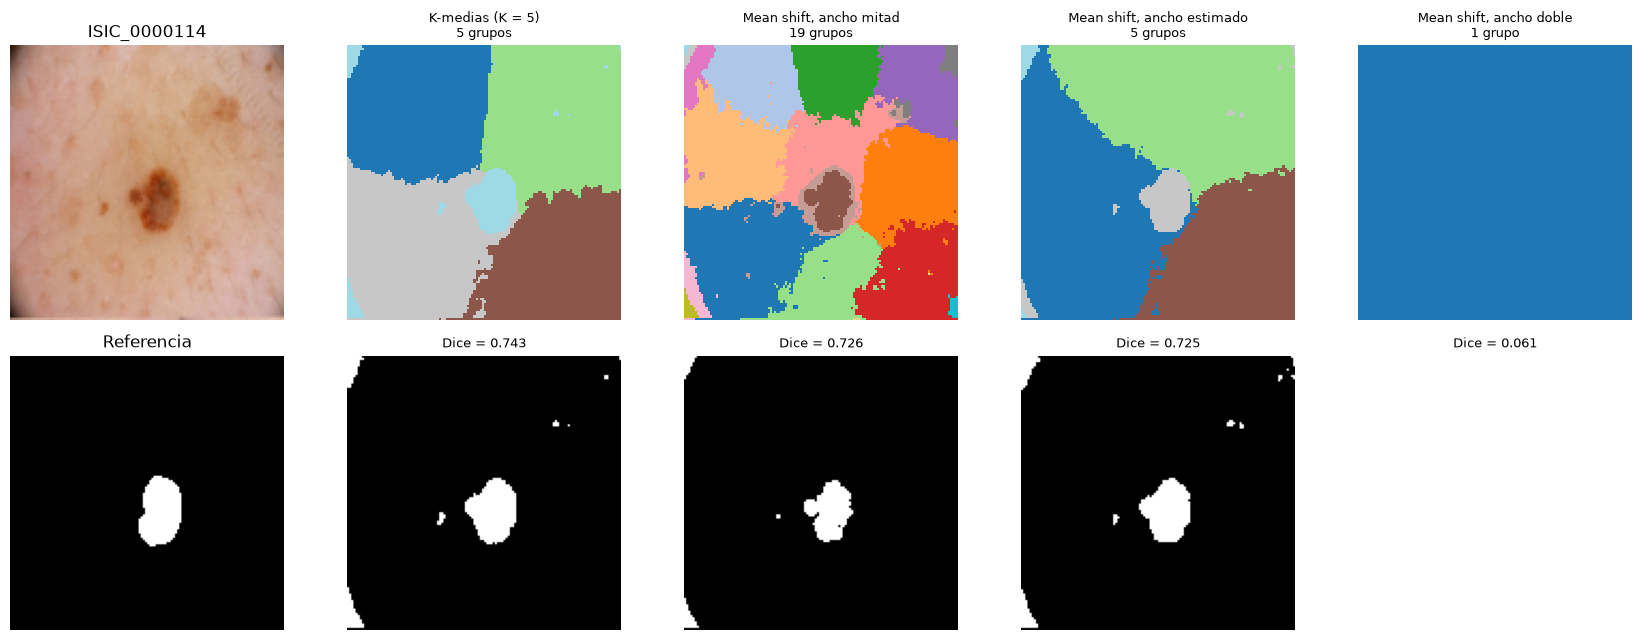

In [ ]:
# Bono B. Mean shift frente a K-medias sobre la misma imagen y la misma representación
import time
from sklearn.cluster import MeanShift, estimate_bandwidth

NOMBRE_BONO = "ISIC_0000114"
i_bono = nombres_ajuste.index(NOMBRE_BONO)
j_bono = nombres_comb.index("λ/β = 0.5")          # β = 1, λ = 0.5
cfg = COMBINACIONES[j_bono]
img_b, ref_b = imgs_ajuste[i_bono], masks_ajuste[i_bono]
X_b = construir_pipeline(beta=cfg["beta"], lam=cfg["lam"]).fit_transform(img_b)

# Mean shift se ajusta con una muestra de 3000 píxeles y luego asigna los 16384 al centro más cercano
rng_b = np.random.default_rng(SEMILLA)
idx_b = rng_b.choice(X_b.shape[0], size=3000, replace=False)
ancho_est = estimate_bandwidth(X_b[idx_b], quantile=0.2, n_samples=500, random_state=SEMILLA)

# K-medias con el K elegido por la silueta, como en el resto del laboratorio
k_b = resultados[(i_bono, j_bono)]["k_opt"]
t0 = time.perf_counter()
km_b = KMeans(n_clusters=k_b, n_init=N_INIT, random_state=SEMILLA).fit(X_b)
t_km = time.perf_counter() - t0
etq_km = km_b.labels_.astype(np.int8)
masc_km = mascara_criterio_a(img_b, etq_km)

filas_b = [{"método": f"K-medias (K = {k_b})", "ancho de banda": np.nan, "grupos": k_b,
            "Dice": dice(masc_km, ref_b), "tiempo (s)": t_km}]
etiquetas_b, mascaras_b = {f"K-medias (K = {k_b})": etq_km}, {f"K-medias (K = {k_b})": masc_km}

for nombre, bw in [("mitad", ancho_est / 2), ("estimado", ancho_est), ("doble", ancho_est * 2)]:
    t0 = time.perf_counter()
    ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(X_b[idx_b])
    etq_ms = ms.predict(X_b).astype(np.int16)
    t_ms = time.perf_counter() - t0
    masc_ms = mascara_criterio_a(img_b, etq_ms)
    clave = f"Mean shift, ancho {nombre}"
    etiquetas_b[clave], mascaras_b[clave] = etq_ms, masc_ms
    filas_b.append({"método": clave, "ancho de banda": bw, "grupos": len(np.unique(etq_ms)),
                    "Dice": dice(masc_ms, ref_b), "tiempo (s)": t_ms})

tabla_b = pd.DataFrame(filas_b).set_index("método")
print(f"Imagen: {NOMBRE_BONO} | β = {cfg['beta']}, λ = {cfg['lam']} | ancho estimado (cuantil 0.2): {ancho_est:.3f}")
display(tabla_b.round(3))

claves = list(etiquetas_b)
fig, axes = plt.subplots(2, len(claves) + 1, figsize=(17, 6.5))
axes[0, 0].imshow(img_b); axes[0, 0].set_title(NOMBRE_BONO)
axes[1, 0].imshow(ref_b, cmap="gray", vmin=0, vmax=1); axes[1, 0].set_title("Referencia")
for c, clave in enumerate(claves, start=1):
    g = etiquetas_b[clave].reshape(TAMANO[1], TAMANO[0])
    axes[0, c].imshow(g, cmap="tab20", interpolation="nearest")
    n_g = len(np.unique(g))
    axes[0, c].set_title(f"{clave}\n{n_g} grupo{'s' if n_g != 1 else ''}", fontsize=9)
    axes[1, c].imshow(mascaras_b[clave], cmap="gray", vmin=0, vmax=1)
    axes[1, c].set_title(f"Dice = {dice(mascaras_b[clave], ref_b):.3f}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

#### Comparación con K-medias

Con el ancho estimado, de 0.202, mean shift encontró 5 grupos y un Dice de 0.725, frente a 0.743 de K-medias. Es una diferencia pequeña, de una sola imagen, que no permite decir que un método sea mejor que el otro. Con la mitad del ancho, 0.101, encontró 19 grupos y el Dice casi no cambió, 0.726, porque el criterio A reúne los grupos de alto contraste y la lesión sigue quedando en la máscara. Con el doble, 0.404, todo se fundió en un solo grupo, la máscara cubrió toda la imagen y el Dice cayó a 0.061.

En tiempo, K-medias tardó unos 0.04 s ajustándose con los 16384 píxeles. Mean shift tardó unos 0.2 s con el ancho estimado y unos 0.65 s con la mitad del ancho, aun ajustándose solo con 3000 píxeles. En cada iteración cada punto busca vecinos, y cuanto más pequeño es el ancho, más modos y más trabajo. Con imágenes más grandes el costo crece rápido, y por eso tuvimos que submuestrear. Los tiempos cambian un poco de una ejecución a otra.

En resumen, mean shift evita elegir K pero lo cambia por elegir el ancho de banda, y el resultado depende mucho de él. Para esta imagen no mejora a K-medias y es más lento.